# Inferência Neurofisiológica e Fisiológica (Tarefa de Stroop)

Este passo cruza os dados demográficos da amostra analítica rigorosa ($N=51$, excluindo atletas de modalidades individuais) com os descritores biológicos extraídos durante a tarefa de Stroop (variáveis hemodinâmicas do fNIRS e biossinais periféricos SPA).

**Estratégia Analítica:**
1. **Filtro de Variáveis:** Isolamento automático de concentrações e amplitudes (`HbO_*_Beta`, `GSR_*`, `HR_*`), ignorando p-values do GLM de 1º nível e canais rejeitados.
2. **Estatística de Contraste:** Aplicação do **Teste *t* de Welch** para amostras independentes, adequado para lidar com a heterogeneidade de variâncias e as ligeiras assimetrias na dimensão dos grupos (A vs. C; AB vs. C).
3. **Magnitude das Diferenças:** Cálculo do **Hedges' *g*** para o tamanho do efeito, por ser o estimador mais robusto para amostras com $N < 50$ por braço.
4. **Controlo de Erro (FDR):** Aplicação da correção de **Holm-Bonferroni** ao valor de $p$ para controlar o Erro do Tipo I face às múltiplas comparações (dezenas de canais medidos em simultâneo).

In [6]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (À Prova de Balas)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"

caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline inferencial para os dados SPA-fNIRS (Stroop)...")

# Ler Base Demográfica
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

# Ler Base Stroop (Lidar com CSVs em português: separador ';' e decimais ',')
if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5:  # Se falhou a leitura por ';', tentar o padrão americano
        df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Padronização de IDs e Definição da Amostra (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

# Limpeza de IDs (garante que "1.0" , "1" e " 1 " ficam exatamente iguais)
df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

print(f"-> Sujeitos no Demográfico: {len(df_demo)}")
print(f"-> Sujeitos no Stroop fNIRS: {len(df_stroop)}")

# Padronização e Exclusão
df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# Grupos
df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB'

df_mapeamento = pd.concat([
    df_analitica[['ID_Clean', 'Grupo_Análise']],
    df_fut[['ID_Clean', 'Grupo_Análise']]
], ignore_index=True)

# ==========================================================
# 3. Merge e Tratamento Forçado de Variáveis
# ==========================================================
df_master = pd.merge(df_mapeamento, df_stroop, on='ID_Clean', how='inner')
print(f"-> Merge concluído! Cruzamos perfis com dados fNIRS de {len(df_master['ID_Clean'].unique())} sujeitos válidos.")

# Encontrar as colunas biológicas APENAS PELO NOME (resolve o problema do Pandas)
variaveis_alvo = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

# Forçar para Numérico: substituir possíveis vírgulas europeias por pontos e converter
for var in variaveis_alvo:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

print(f"-> Analisando {len(variaveis_alvo)} variáveis neurofisiológicas em segurança...\n")

# ==========================================================
# 4. Estatística Inferencial: Welch t-test & Hedges' g (Ultra Robusto)
# ==========================================================
resultados = []

def extrair_stats(res_df):
    """Extrai t, gl, p-value e tamanho de efeito ignorando variações de nome na biblioteca."""
    if res_df is None or res_df.empty:
        return np.nan, np.nan, np.nan, np.nan
        
    cols = [str(c).lower().strip() for c in res_df.columns]
    
    # 1. Encontrar T
    try:
        col_t = res_df.columns[[i for i, c in enumerate(cols) if c in ['t', 't-val', 'tval']][0]]
    except IndexError:
        col_t = res_df.columns[0] # Posição habitual
        
    # 2. Encontrar Graus de Liberdade (dof)
    try:
        col_dof = res_df.columns[[i for i, c in enumerate(cols) if 'dof' in c or 'df' in c][0]]
    except IndexError:
        col_dof = res_df.columns[1] # Posição habitual
        
    # 3. Encontrar P-value
    try:
        col_p = res_df.columns[[i for i, c in enumerate(cols) if c in ['p-val', 'pval', 'p', 'p-value'] or c.startswith('p')][0]]
    except IndexError:
        col_p = res_df.columns[3] # Posição habitual
        
    # 4. Encontrar Tamanho de Efeito
    try:
        col_es = res_df.columns[[i for i, c in enumerate(cols) if 'hedge' in c or 'cohen' in c or 'es' in c or c == 'd'][0]]
    except IndexError:
        col_es = res_df.columns[5] # Posição habitual
        
    return res_df[col_t].values[0], res_df[col_dof].values[0], res_df[col_p].values[0], res_df[col_es].values[0]

for var in variaveis_alvo:
    df_var = df_master[['Grupo_Análise', var]].dropna()
    
    x_A = df_var[df_var['Grupo_Análise'] == 'A'][var].values
    x_AB = df_var[df_var['Grupo_Análise'] == 'AB'][var].values
    x_C = df_var[df_var['Grupo_Análise'] == 'C'][var].values
    
    # 4.1 Contraste: Grupo A vs C
    if len(x_A) >= 3 and len(x_C) >= 3:
        try:
            res_AC = pg.ttest(x_A, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_AC)
            
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo A vs C',
                    'N_G1': len(x_A), 'Média_G1': np.mean(x_A), 'DP_G1': np.std(x_A, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val,
                    'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception:
            pass # Ignorar se o teste falhar (ex: dados constantes/variância zero nesta variável)
        
    # 4.2 Contraste: Subgrupo AB vs C
    if len(x_AB) >= 3 and len(x_C) >= 3:
        try:
            res_ABC = pg.ttest(x_AB, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_ABC)
            
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo AB vs C',
                    'N_G1': len(x_AB), 'Média_G1': np.mean(x_AB), 'DP_G1': np.std(x_AB, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val,
                    'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception:
            pass

df_res = pd.DataFrame(resultados)

# ==========================================================
# 5. Correção de Holm-Bonferroni (FDR)
# ==========================================================
if not df_res.empty:
    df_AC = df_res[df_res['Contraste'] == 'Grupo A vs C'].copy()
    df_ABC = df_res[df_res['Contraste'] == 'Grupo AB vs C'].copy()
    
    # Holm A vs C
    if not df_AC.empty:
        rej_AC, pval_corr_AC = pg.multicomp(df_AC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_AC['p-Holm'] = pval_corr_AC
        df_AC['Significativo'] = rej_AC
    
    # Holm AB vs C
    if not df_ABC.empty:
        rej_ABC, pval_corr_ABC = pg.multicomp(df_ABC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_ABC['p-Holm'] = pval_corr_ABC
        df_ABC['Significativo'] = rej_ABC
    
    # Agrupar e ordenar a tabela final
    df_final = pd.concat([df_AC, df_ABC]).sort_values(by=['Variável', 'Contraste'])
    
    cols_format = ['Média_G1', 'DP_G1', 'Média_G2', 'DP_G2', 't', 'gl', 'p-uncorrected', 'p-Holm', 'Hedges_g']
    df_final[cols_format] = df_final[cols_format].round(4)
    
    ficheiro_saida = pasta_resultados / "Comparacoes_Neurofisiologicas_Welch_Holm_Stroop.xlsx"
    df_final.to_excel(ficheiro_saida, index=False)
    
    print("="*60)
    print("ANÁLISE INFERENCIAL CONCLUÍDA (STROOP: fNIRS + Fisiologia)")
    print("="*60)
    print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")
    
    achados = df_final[df_final['Significativo'] == True]
    if not achados.empty:
        print("[!] Achados Estatisticamente Significativos (p-Holm < 0.05):")
        from IPython.display import display
        display(achados[['Variável', 'Contraste', 'Média_G1', 'Média_G2', 'p-Holm', 'Hedges_g']])
    else:
        print("[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).")
else:
    print("Não foram gerados resultados para exportar.")

A iniciar o pipeline inferencial para os dados SPA-fNIRS (Stroop)...
-> Sujeitos no Demográfico: 54
-> Sujeitos no Stroop fNIRS: 53
-> Merge concluído! Cruzamos perfis com dados fNIRS de 50 sujeitos válidos.
-> Analisando 68 variáveis neurofisiológicas em segurança...

ANÁLISE INFERENCIAL CONCLUÍDA (STROOP: fNIRS + Fisiologia)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_Stroop.xlsx

[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).


# Inferência Neurofisiológica e Fisiológica (Tarefa de Decision Making)

Aplicação do pipeline inferencial validado à tarefa de Tomada de Decisão (Decision Making). Cruzamento dos dados demográficos da amostra analítica ($N=51$) com os descritores biológicos (fNIRS e SPA).

**Estratégia Analítica:**
1. **Filtro de Variáveis Biológicas** (`HbO_*_Beta`, `GSR_*`, `HR_*`).
2. **Estatística de Contraste:** Teste *t* de Welch para amostras independentes (A vs. C; AB vs. C).
3. **Tamanho do Efeito:** Cálculo do Hedges' *g*.
4. **Controlo de Erro (FDR):** Correção de Holm-Bonferroni aplicada de forma independente a cada família de contrastes.

In [1]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (Decision Making)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"

caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline inferencial para os dados SPA-fNIRS (DECISION MAKING)...")

# Ler Base Demográfica
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

# Ler Base Decision Making
if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5:  
        df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# ==========================================================
# 2. Padronização de IDs e Definição da Amostra (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

print(f"-> Sujeitos no Demográfico: {len(df_demo)}")
print(f"-> Sujeitos no Decision Making fNIRS: {len(df_dm)}")

# Padronização e Exclusão
df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# Grupos
df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB'

df_mapeamento = pd.concat([
    df_analitica[['ID_Clean', 'Grupo_Análise']],
    df_fut[['ID_Clean', 'Grupo_Análise']]
], ignore_index=True)

# ==========================================================
# 3. Merge e Tratamento Forçado de Variáveis
# ==========================================================
df_master = pd.merge(df_mapeamento, df_dm, on='ID_Clean', how='inner')
print(f"-> Merge concluído! Cruzamos perfis com dados de {len(df_master['ID_Clean'].unique())} sujeitos válidos.")

variaveis_alvo = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

for var in variaveis_alvo:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

print(f"-> Analisando {len(variaveis_alvo)} variáveis neurofisiológicas em segurança...\n")

# ==========================================================
# 4. Estatística Inferencial (Função Robusta)
# ==========================================================
resultados = []

def extrair_stats(res_df):
    if res_df is None or res_df.empty: return np.nan, np.nan, np.nan, np.nan
    cols = [str(c).lower().strip() for c in res_df.columns]
    try: col_t = res_df.columns[[i for i, c in enumerate(cols) if c in ['t', 't-val', 'tval']][0]]
    except IndexError: col_t = res_df.columns[0]
    try: col_dof = res_df.columns[[i for i, c in enumerate(cols) if 'dof' in c or 'df' in c][0]]
    except IndexError: col_dof = res_df.columns[1]
    try: col_p = res_df.columns[[i for i, c in enumerate(cols) if c in ['p-val', 'pval', 'p', 'p-value'] or c.startswith('p')][0]]
    except IndexError: col_p = res_df.columns[3]
    try: col_es = res_df.columns[[i for i, c in enumerate(cols) if 'hedge' in c or 'cohen' in c or 'es' in c or c == 'd'][0]]
    except IndexError: col_es = res_df.columns[5]
    return res_df[col_t].values[0], res_df[col_dof].values[0], res_df[col_p].values[0], res_df[col_es].values[0]

for var in variaveis_alvo:
    df_var = df_master[['Grupo_Análise', var]].dropna()
    x_A = df_var[df_var['Grupo_Análise'] == 'A'][var].values
    x_AB = df_var[df_var['Grupo_Análise'] == 'AB'][var].values
    x_C = df_var[df_var['Grupo_Análise'] == 'C'][var].values
    
    if len(x_A) >= 3 and len(x_C) >= 3:
        try:
            res_AC = pg.ttest(x_A, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_AC)
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo A vs C',
                    'N_G1': len(x_A), 'Média_G1': np.mean(x_A), 'DP_G1': np.std(x_A, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val, 'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception: pass
        
    if len(x_AB) >= 3 and len(x_C) >= 3:
        try:
            res_ABC = pg.ttest(x_AB, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_ABC)
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo AB vs C',
                    'N_G1': len(x_AB), 'Média_G1': np.mean(x_AB), 'DP_G1': np.std(x_AB, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val, 'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception: pass

df_res = pd.DataFrame(resultados)

# ==========================================================
# 5. Correção de Holm-Bonferroni (FDR) e Exportação
# ==========================================================
if not df_res.empty:
    df_AC = df_res[df_res['Contraste'] == 'Grupo A vs C'].copy()
    df_ABC = df_res[df_res['Contraste'] == 'Grupo AB vs C'].copy()
    
    if not df_AC.empty:
        rej_AC, pval_corr_AC = pg.multicomp(df_AC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_AC['p-Holm'] = pval_corr_AC
        df_AC['Significativo'] = rej_AC
    
    if not df_ABC.empty:
        rej_ABC, pval_corr_ABC = pg.multicomp(df_ABC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_ABC['p-Holm'] = pval_corr_ABC
        df_ABC['Significativo'] = rej_ABC
    
    df_final = pd.concat([df_AC, df_ABC]).sort_values(by=['Variável', 'Contraste'])
    cols_format = ['Média_G1', 'DP_G1', 'Média_G2', 'DP_G2', 't', 'gl', 'p-uncorrected', 'p-Holm', 'Hedges_g']
    df_final[cols_format] = df_final[cols_format].round(4)
    
    ficheiro_saida = pasta_resultados / "Comparacoes_Neurofisiologicas_Welch_Holm_DecisionMaking.xlsx"
    df_final.to_excel(ficheiro_saida, index=False)
    
    print("="*60)
    print("ANÁLISE INFERENCIAL CONCLUÍDA (DECISION MAKING: fNIRS + Fisiologia)")
    print("="*60)
    print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")
    
    achados = df_final[df_final['Significativo'] == True]
    if not achados.empty:
        print("[!] Achados Estatisticamente Significativos (p-Holm < 0.05):")
        from IPython.display import display
        display(achados[['Variável', 'Contraste', 'Média_G1', 'Média_G2', 'p-Holm', 'Hedges_g']])
    else:
        print("[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).")
else:
    print("Não foram gerados resultados para exportar.")

A iniciar o pipeline inferencial para os dados SPA-fNIRS (DECISION MAKING)...
-> Sujeitos no Demográfico: 54
-> Sujeitos no Decision Making fNIRS: 54
-> Merge concluído! Cruzamos perfis com dados de 51 sujeitos válidos.
-> Analisando 24 variáveis neurofisiológicas em segurança...

ANÁLISE INFERENCIAL CONCLUÍDA (DECISION MAKING: fNIRS + Fisiologia)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_DecisionMaking.xlsx

[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).


# V2 — Inferência neurofisiológica e fisiológica

Esta análise compara os grupos A e C e os grupos AB e C, separadamente
para as tarefas de Stroop e Decision Making.

- Grupo A: atletas federados de modalidades coletivas.
- Grupo AB: subgrupo de futebolistas do Grupo A.
- Grupo C: participantes atualmente não federados.

## Estratégia analítica

1. Seleção das variáveis HbO_*_Beta, GSR_* e HR_*.
2. Testes t de Welch bilaterais para amostras independentes.
3. Cálculo explícito de Hedges' g com sinal, segundo G1 menos G2.
4. Correção de Holm para controlo do erro familiar (FWER).
5. Uma família de correção por tarefa e contraste, reunindo todas
   as variáveis selecionadas que tenham testes estimáveis.
6. Exportação sem arredondamento prévio dos resultados.
7. Auditoria dos participantes, valores ausentes e testes não estimáveis.

A análise pressupõe uma linha por participante em cada dataset.
Os canais rejeitados no processamento anterior devem estar representados
por valores ausentes; este código não realiza novo controlo de qualidade
dos sinais.

Os intervalos de confiança de 95% referem-se à diferença de médias
e não estão ajustados para comparações múltiplas.

In [1]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats
from IPython.display import display

PASTA_DADOS = Path("../data_subjects")
PASTA_RESULTADOS = PASTA_DADOS / "V2_Resultados_Neurofisiologicos"
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05
MIN_N = 3

COL_ESTATUTO = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)
COL_MODALIDADE = "Indique a modalidade principal"
COL_TIPO = (
    "No caso de ser desportista federado, a sua modalidade principal é:"
)

print("Pasta de entrada:", PASTA_DADOS.resolve())
print("Pasta de resultados:", PASTA_RESULTADOS.resolve())
print("Versão de Pingouin:", pg.__version__)

Pasta de entrada: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects
Pasta de resultados: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\V2_Resultados_Neurofisiologicos
Versão de Pingouin: 0.7.0


## Preparação da amostra analítica

Os identificadores são padronizados e verificados para impedir duplicações.

São excluídos os atletas atualmente federados em modalidades individuais.
A amostra analítica esperada é de 51 participantes:

- Grupo A: 28 participantes.
- Grupo AB: 22 futebolistas, incluídos no Grupo A.
- Grupo C: 23 participantes.

A pertença simultânea aos grupos A e AB não duplica participantes
dentro de uma comparação: os contrastes são calculados separadamente.

O número efetivamente disponível em cada tarefa ou variável pode ser
inferior ao número de participantes elegíveis.

In [2]:
def normalizar_texto(valor):
    if pd.isna(valor):
        return ""

    texto = str(valor).strip().casefold()

    return "".join(
        caractere
        for caractere in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caractere)
    )


def limpar_id(valor):
    if pd.isna(valor):
        raise ValueError("Foi encontrado um ID ausente.")

    texto = str(valor).strip()

    if not texto:
        raise ValueError("Foi encontrado um ID vazio.")

    # Mantém a lógica dos scripts originais:
    # 1.0 -> 1; não altera identificadores alfanuméricos.
    if texto.endswith(".0") and texto[:-2].isdigit():
        texto = texto[:-2]

    return texto


def preparar_ids(df, nome_origem):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()

    if df.columns.duplicated().any():
        raise ValueError(
            f"Existem nomes de colunas duplicados em {nome_origem}."
        )

    coluna_id = "ID" if "ID" in df.columns else df.columns[0]
    df["ID_Clean"] = df[coluna_id].map(limpar_id)

    duplicados = df.loc[
        df["ID_Clean"].duplicated(keep=False),
        "ID_Clean"
    ].tolist()

    if duplicados:
        raise ValueError(
            f"IDs duplicados em {nome_origem}: {duplicados}. "
            "É necessária uma linha por participante. "
            "Se existem várias runs, agregá-las segundo o plano analítico "
            "antes de executar esta análise."
        )

    return df


caminho_demo = PASTA_DADOS / "Merge_Dataset_Study_2.xlsx"

with pd.ExcelFile(caminho_demo) as excel:
    folha = (
        "Merge Dataset"
        if "Merge Dataset" in excel.sheet_names
        else excel.sheet_names[0]
    )
    df_demo = pd.read_excel(excel, sheet_name=folha)

df_demo = preparar_ids(df_demo, caminho_demo.name)

colunas_obrigatorias = [
    COL_ESTATUTO,
    COL_MODALIDADE,
    COL_TIPO
]

faltam = [
    coluna
    for coluna in colunas_obrigatorias
    if coluna not in df_demo.columns
]

if faltam:
    raise KeyError(
        f"Faltam colunas demográficas: {faltam}. "
        "Não será feita uma classificação automática por exclusão."
    )

estatuto = df_demo[COL_ESTATUTO].map(normalizar_texto)
modalidade = df_demo[COL_MODALIDADE].map(normalizar_texto)
tipo = df_demo[COL_TIPO].map(normalizar_texto)

estatuto_invalido = ~estatuto.isin(["sim", "nao"])

if estatuto_invalido.any():
    display(
        df_demo.loc[
            estatuto_invalido,
            ["ID_Clean", COL_ESTATUTO]
        ]
    )
    raise ValueError("Rever valores inválidos no estatuto federado.")

federado = estatuto.eq("sim")
individual = tipo.str.contains("individual", regex=False)
coletivo = tipo.str.contains("coletiv", regex=False)

tipo_ambiguo = federado & (individual == coletivo)

if tipo_ambiguo.any():
    display(
        df_demo.loc[
            tipo_ambiguo,
            ["ID_Clean", COL_MODALIDADE, COL_TIPO]
        ]
    )
    raise ValueError(
        "Há atletas federados sem classificação inequívoca "
        "como modalidade individual ou coletiva."
    )

excluir = federado & individual

df_excluidos = df_demo.loc[
    excluir,
    ["ID_Clean", COL_MODALIDADE, COL_TIPO]
].copy()

df_grupos = df_demo.loc[
    ~excluir,
    ["ID_Clean"]
].copy()

df_grupos["Grupo_Base"] = np.where(
    estatuto.loc[df_grupos.index].eq("sim"),
    "A",
    "C"
)

df_grupos["Futebolista"] = (
    df_grupos["Grupo_Base"].eq("A")
    & modalidade.loc[df_grupos.index].eq("futebol")
)

contagens = {
    "A": int(df_grupos["Grupo_Base"].eq("A").sum()),
    "AB": int(df_grupos["Futebolista"].sum()),
    "C": int(df_grupos["Grupo_Base"].eq("C").sum())
}

print("Participantes na base demográfica:", len(df_demo))
print("Excluídos por modalidade individual:", len(df_excluidos))
print("Participantes analíticos elegíveis:", len(df_grupos))
print("Dimensão dos grupos:", contagens)

if len(df_grupos) != 51 or contagens != {"A": 28, "AB": 22, "C": 23}:
    raise ValueError(
        "A amostra não corresponde à composição esperada. "
        "Rever a classificação antes de continuar."
    )

Participantes na base demográfica: 54
Excluídos por modalidade individual: 3
Participantes analíticos elegíveis: 51
Dimensão dos grupos: {'A': 28, 'AB': 22, 'C': 23}


## Análise comum às duas tarefas

Para cada tarefa:

1. Carregar o dataset e confirmar a existência de uma linha por participante.
2. Cruzar os dados biológicos com os participantes elegíveis.
3. Selecionar as variáveis HbO_*_Beta, GSR_* e HR_*.
4. Documentar valores ausentes, infinitos e falhas de conversão numérica.
5. Calcular os contrastes A–C e AB–C com os casos disponíveis em cada variável.
6. Aplicar Holm separadamente a cada contraste.
7. Exportar resultados e tabelas de auditoria.

Hedges' g positivo significa média superior em A ou AB relativamente a C.
Hedges' g negativo significa média inferior em A ou AB relativamente a C.

Os valores ausentes são documentados, mas a sua causa deve ser verificada
no processamento original dos dados.

A seleção pelo nome das colunas não identifica automaticamente canais
rejeitados nem distingue variáveis primárias de variáveis auxiliares.
A lista de variáveis selecionadas é exportada para revisão.

In [3]:
def ler_dataset_biologico(nome_base):
    caminho_csv = PASTA_DADOS / f"{nome_base}.csv"
    caminho_xlsx = PASTA_DADOS / f"{nome_base}.xlsx"

    if caminho_csv.exists():
        df = pd.read_csv(
            caminho_csv,
            sep=";",
            decimal=",",
            encoding="utf-8-sig"
        )

        if len(df.columns) < 5:
            df = pd.read_csv(
                caminho_csv,
                sep=",",
                decimal=".",
                encoding="utf-8-sig"
            )

        caminho = caminho_csv

    elif caminho_xlsx.exists():
        df = pd.read_excel(caminho_xlsx)
        caminho = caminho_xlsx

    else:
        raise FileNotFoundError(
            f"Não foi encontrado {caminho_csv} nem {caminho_xlsx}."
        )

    return preparar_ids(df, caminho.name), caminho


def exportar_excel(caminho, folhas):
    with pd.ExcelWriter(caminho, engine="openpyxl") as writer:
        for nome, tabela in folhas.items():
            tabela.to_excel(
                writer,
                sheet_name=nome,
                index=False
            )

            ws = writer.sheets[nome]
            ws.freeze_panes = "A2"

            if len(tabela.columns):
                ws.auto_filter.ref = ws.dimensions

            for coluna in ws.columns:
                letra = coluna[0].column_letter
                ws.column_dimensions[letra].width = 24

                for celula in coluna[1:]:
                    if isinstance(celula.value, float):
                        celula.number_format = "0.000000E+00"


def analisar_tarefa(tarefa, nome_base):
    df_bio, caminho_origem = ler_dataset_biologico(nome_base)

    variaveis = [
        coluna
        for coluna in df_bio.columns
        if (
            coluna.startswith("GSR_")
            or coluna.startswith("HR_")
            or (
                coluna.startswith("HbO_")
                and coluna.endswith("_Beta")
            )
        )
    ]

    if not variaveis:
        raise ValueError(
            f"Não foram encontradas variáveis-alvo em {tarefa}."
        )

    df_master = pd.merge(
        df_grupos,
        df_bio[["ID_Clean"] + variaveis],
        on="ID_Clean",
        how="left",
        validate="one_to_one",
        indicator=True
    )

    df_presenca = df_master[
        ["ID_Clean", "Grupo_Base", "Futebolista", "_merge"]
    ].copy()

    df_presenca["_merge"] = df_presenca["_merge"].astype(str)

    df_presenca = df_presenca.rename(
        columns={"_merge": "Presenca"}
    )

    df_fora_amostra = df_bio.loc[
        ~df_bio["ID_Clean"].isin(df_grupos["ID_Clean"]),
        ["ID_Clean"]
    ].copy()

    conversoes_invalidas = []

    for variavel in variaveis:
        original = df_master[variavel]

        texto = (
            original.astype("string")
            .str.strip()
            .str.replace(",", ".", regex=False)
        )

        numerico = pd.to_numeric(texto, errors="coerce")
        numerico = numerico.astype(float)

        falhou = original.notna() & numerico.isna()
        infinito = pd.Series(
            np.isinf(numerico.to_numpy()),
            index=df_master.index
        )

        for indice in df_master.index[falhou | infinito]:
            conversoes_invalidas.append({
                "ID_Clean": df_master.at[indice, "ID_Clean"],
                "Variavel": variavel,
                "Valor_original": str(original.loc[indice]),
                "Motivo": (
                    "Valor infinito"
                    if infinito.loc[indice]
                    else "Conversao numerica falhou"
                )
            })

        df_master[variavel] = numerico.mask(infinito)

    resultados = []
    auditoria = []
    testes_nao_estimaveis = []

    mascaras = {
        "A": df_master["Grupo_Base"].eq("A"),
        "AB": df_master["Futebolista"],
        "C": df_master["Grupo_Base"].eq("C")
    }

    for variavel in variaveis:
        for grupo, mascara in mascaras.items():
            valores = df_master.loc[
                mascara, variavel
            ].dropna()

            ids_ausentes = df_master.loc[
                mascara & df_master[variavel].isna(),
                "ID_Clean"
            ].tolist()

            auditoria.append({
                "Variavel": variavel,
                "Grupo": grupo,
                "N_elegivel": int(mascara.sum()),
                "N_valido": len(valores),
                "N_ausente": len(ids_ausentes),
                "IDs_ausentes": ", ".join(ids_ausentes),
                "Minimo": valores.min(),
                "Maximo": valores.max(),
                "Mediana": valores.median()
            })

        for grupo in ["A", "AB"]:
            x = df_master.loc[
                mascaras[grupo], variavel
            ].dropna().to_numpy(dtype=float)

            y = df_master.loc[
                mascaras["C"], variavel
            ].dropna().to_numpy(dtype=float)

            base = {
                "Tarefa": tarefa,
                "Variável": variavel,
                "Contraste": f"Grupo {grupo} vs C",
                "Familia_Holm": f"{tarefa}_{grupo}_vs_C",
                "N_G1": len(x),
                "N_G2": len(y)
            }

            if min(len(x), len(y)) < MIN_N:
                testes_nao_estimaveis.append({
                    **base,
                    "Motivo": "Menos de 3 observacoes num grupo"
                })
                continue

            nx = len(x)
            ny = len(y)

            media_x = np.mean(x)
            media_y = np.mean(y)

            variancia_x = np.var(x, ddof=1)
            variancia_y = np.var(y, ddof=1)

            if variancia_x == 0 and variancia_y == 0:
                testes_nao_estimaveis.append({
                    **base,
                    "Motivo": "Variancia zero nos dois grupos"
                })
                continue

            # Teste de Welch bilateral.
            erro_padrao_quadrado = (
                variancia_x / nx
                + variancia_y / ny
            )

            erro_padrao = np.sqrt(erro_padrao_quadrado)

            graus_liberdade = (
                erro_padrao_quadrado ** 2
                / (
                    (variancia_x / nx) ** 2 / (nx - 1)
                    + (variancia_y / ny) ** 2 / (ny - 1)
                )
            )

            diferenca = media_x - media_y
            t_valor = diferenca / erro_padrao

            p_valor = 2 * stats.t.sf(
                np.abs(t_valor),
                df=graus_liberdade
            )

            # IC95% pontual da diferença de médias.
            margem = (
                stats.t.ppf(0.975, df=graus_liberdade)
                * erro_padrao
            )

            # Hedges' g assinado, calculado explicitamente.
            hedges_g = pg.compute_effsize(
                x,
                y,
                paired=False,
                eftype="hedges"
            )

            if not np.all(np.isfinite([
                t_valor,
                graus_liberdade,
                p_valor,
                hedges_g
            ])):
                raise ValueError(
                    f"Resultado nao finito: {tarefa}, "
                    f"{variavel}, {grupo} vs C."
                )

            resultados.append({
                **base,
                "Média_G1": media_x,
                "DP_G1": np.sqrt(variancia_x),
                "Média_G2": media_y,
                "DP_G2": np.sqrt(variancia_y),
                "Diferenca_G1_menos_G2": diferenca,
                "IC95_diferenca_inf": diferenca - margem,
                "IC95_diferenca_sup": diferenca + margem,
                "t": t_valor,
                "gl": graus_liberdade,
                "p-uncorrected": p_valor,
                "Hedges_g": hedges_g
            })

    df_resultados = pd.DataFrame(resultados)

    if df_resultados.empty:
        raise ValueError(
            f"Nenhum teste estimavel para {tarefa}."
        )

    df_resultados["p-Holm"] = np.nan
    df_resultados["Significativo"] = False
    df_resultados["N_testes_familia"] = 0

    # Uma família por tarefa e contraste.
    for familia, indices in df_resultados.groupby(
        "Familia_Holm"
    ).groups.items():

        rejeitar, p_corrigidos = pg.multicomp(
            df_resultados.loc[
                indices, "p-uncorrected"
            ].to_numpy(),
            alpha=ALPHA,
            method="holm"
        )

        df_resultados.loc[
            indices, "p-Holm"
        ] = p_corrigidos

        df_resultados.loc[
            indices, "Significativo"
        ] = rejeitar

        df_resultados.loc[
            indices, "N_testes_familia"
        ] = len(indices)

    df_resultados = df_resultados.sort_values(
        ["Variável", "Contraste"]
    ).reset_index(drop=True)

    df_resumo = (
        df_resultados.groupby("Familia_Holm")
        .agg(
            N_testes=("p-uncorrected", "size"),
            Menor_p_original=("p-uncorrected", "min"),
            Menor_p_Holm=("p-Holm", "min"),
            N_significativos=("Significativo", "sum")
        )
        .reset_index()
    )

    df_variaveis = pd.DataFrame({
        "Variavel": variaveis,
        "Tipo": [
            "HbO"
            if v.startswith("HbO_")
            else "GSR"
            if v.startswith("GSR_")
            else "HR"
            for v in variaveis
        ]
    })

    df_configuracao = pd.DataFrame([
        {"Opcao": "Tarefa", "Valor": tarefa},
        {"Opcao": "Origem", "Valor": str(caminho_origem.resolve())},
        {"Opcao": "Alpha", "Valor": str(ALPHA)},
        {"Opcao": "Teste", "Valor": "Welch bilateral"},
        {"Opcao": "Efeito", "Valor": "Hedges g assinado: G1 menos G2"},
        {
            "Opcao": "Correcao",
            "Valor": "Holm; FWER por tarefa e contraste"
        },
        {
            "Opcao": "Familias",
            "Valor": "Todas as variaveis estimaveis do mesmo contraste"
        },
        {
            "Opcao": "IC95",
            "Valor": "Diferenca de medias; nao ajustado para multiplicidade"
        },
        {
            "Opcao": "Qualidade dos canais",
            "Valor": "Deve ter sido avaliada antes desta analise"
        },
        {"Opcao": "Pingouin", "Valor": pg.__version__}
    ])

    nome_saida = (
        f"Comparacoes_Neurofisiologicas_Welch_Holm_{tarefa}"
    )

    caminho_excel = PASTA_RESULTADOS / f"{nome_saida}.xlsx"
    caminho_csv = PASTA_RESULTADOS / f"{nome_saida}.csv"

    # Não arredondar os valores antes de guardar.
    df_resultados.to_csv(
        caminho_csv,
        index=False,
        sep=";",
        decimal=",",
        float_format="%.17g"
    )

    exportar_excel(
        caminho_excel,
        {
            "Resultados": df_resultados,
            "Resumo_Holm": df_resumo,
            "Variaveis_selecionadas": df_variaveis,
            "N_por_variavel": pd.DataFrame(auditoria),
            "Presenca_participantes": df_presenca,
            "Fora_amostra_analitica": df_fora_amostra,
            "Testes_nao_estimaveis": pd.DataFrame(
                testes_nao_estimaveis,
                columns=list(base.keys()) + ["Motivo"]
            ),
            "Conversoes_invalidas": pd.DataFrame(
                conversoes_invalidas,
                columns=[
                    "ID_Clean",
                    "Variavel",
                    "Valor_original",
                    "Motivo"
                ]
            ),
            "Excluidos_desenho": df_excluidos,
            "Configuracao": df_configuracao
        }
    )

    n_com_registo = int(
        df_master["_merge"].eq("both").sum()
    )

    print("=" * 65)
    print(f"ANALISE CONCLUIDA: {tarefa}")
    print("=" * 65)
    print("Participantes elegiveis:", len(df_grupos))
    print("Participantes com registo na tarefa:", n_com_registo)
    print("Variaveis selecionadas:", len(variaveis))
    print("Testes nao estimaveis:", len(testes_nao_estimaveis))
    print("Valores com conversao invalida ou infinitos:",
          len(conversoes_invalidas))
    print()

    display(df_resumo)

    significativos = df_resultados.loc[
        df_resultados["Significativo"]
    ]

    if significativos.empty:
        print(
            "Nao foram encontrados resultados significativos "
            "apos correcao de Holm para controlo da FWER."
        )
    else:
        display(
            significativos[
                [
                    "Variável",
                    "Contraste",
                    "N_G1",
                    "N_G2",
                    "Média_G1",
                    "Média_G2",
                    "p-uncorrected",
                    "p-Holm",
                    "Hedges_g"
                ]
            ]
        )

    print("\nExcel:", caminho_excel.resolve())
    print("CSV:", caminho_csv.resolve())

    return df_resultados, df_resumo

## Inferência neurofisiológica e fisiológica — Stroop

São analisadas as variáveis hemodinâmicas e periféricas selecionadas
no dataset final de Stroop.

Os contrastes A–C e AB–C são calculados separadamente.
A correção de Holm reúne, dentro de cada contraste, todas as variáveis
selecionadas com testes estimáveis.

A dimensão disponível é reportada individualmente por variável.

In [4]:
resultados_stroop, resumo_stroop = analisar_tarefa(
    tarefa="Stroop",
    nome_base="dataset_FINAL_SPA_fNIRS_Stroop"
)

ANALISE CONCLUIDA: Stroop
Participantes elegiveis: 51
Participantes com registo na tarefa: 50
Variaveis selecionadas: 68
Testes nao estimaveis: 0
Valores com conversao invalida ou infinitos: 0



,Familia_Holm,N_testes,Menor_p_original,Menor_p_Holm,N_significativos
0,Stroop_AB_vs_C,68,0.028876,1.0,0
1,Stroop_A_vs_C,68,0.030610,1.0,0


Nao foram encontrados resultados significativos apos correcao de Holm para controlo da FWER.

Excel: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\V2_Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_Stroop.xlsx
CSV: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\V2_Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_Stroop.csv


## Inferência neurofisiológica e fisiológica — Decision Making

São analisadas as variáveis hemodinâmicas e periféricas selecionadas
no dataset final da tarefa de tomada de decisão.

São mantidos os contrastes A–C e AB–C do pipeline original.
O contraste AB–C corresponde especificamente à comparação entre
futebolistas e participantes atualmente não federados.

A correção de Holm é aplicada separadamente a cada contraste,
reunindo todas as variáveis selecionadas com testes estimáveis.

In [6]:
resultados_dm, resumo_dm = analisar_tarefa(
    tarefa="DecisionMaking",
    nome_base="dataset_FINAL_SPA_fNIRS_DecisionMaking"
)

ANALISE CONCLUIDA: DecisionMaking
Participantes elegiveis: 51
Participantes com registo na tarefa: 51
Variaveis selecionadas: 24
Testes nao estimaveis: 0
Valores com conversao invalida ou infinitos: 0



,Familia_Holm,N_testes,Menor_p_original,Menor_p_Holm,N_significativos
0,DecisionMaking_AB_vs_C,24,0.073280,1.0,0
1,DecisionMaking_A_vs_C,24,0.070963,1.0,0


Nao foram encontrados resultados significativos apos correcao de Holm para controlo da FWER.

Excel: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\V2_Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_DecisionMaking.xlsx
CSV: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\V2_Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_DecisionMaking.csv


# Fase 9: Correlações Cérebro-Comportamento (Stroop)

Dado que a inferência baseada na comparação de grupos (Coletivos vs. Não-Atletas) não revelou diferenças significativas após o controlo rigoroso de FDR, a estratégia analítica transita para o estudo de associações contínuas entre a neurofisiologia e o rendimento cognitivo (*Brain-Behavior Correlations*).

**Estratégia Analítica:**
1. **Integração Multimodal:** Fusão dos *outcomes* comportamentais globais da tarefa de Stroop (`ST_Acc_N_Total`, `ST_RT_Medio_Total_seg`) com os descritores biológicos do fNIRS e SPA.
2. **Matriz de Correlações:** Cálculo de correlações de Spearman (robustas a desvios de normalidade e *outliers*) entre o desempenho psicomotor e a ativação cortical/fisiológica, analisando a amostra analítica global ($N=51$).
3. **Controlo de Erro (FDR):** Aplicação de Holm-Bonferroni aos *p-values* da matriz de correlações.
4. **Exportação:** Geração de um relatório com as associações mais fortes (significativas e tendências com moderado tamanho de efeito).

In [3]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"
caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx

pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline de Correlações Cérebro-Comportamento (Stroop)...")

# Ler Base Demográfica
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

# Ler Base Stroop fNIRS
if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5:  
        df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Limpeza de IDs e Filtragem da Amostra (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

# Excluir Individuais
df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# ==========================================================
# 3. Merge: Comportamento + Fisiologia
# ==========================================================
vars_comportamento = ['ID_Clean', 'ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_stroop, on='ID_Clean', how='inner')

variaveis_neuro = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

# Forçar conversão numérica segura
for var in variaveis_neuro + ['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg'])
print(f"-> Analisando correlações para {len(df_master)} sujeitos válidos...\n")

# ==========================================================
# 4. Matriz de Correlação (Spearman) Robusta
# ==========================================================
# Precisão (Accuracy)
corr_acc = pg.pairwise_corr(df_master, columns=[['ST_Acc_N_Total'], variaveis_neuro], method='spearman')

# Extração dinâmica do nome da coluna do p-value
p_col_acc = [c for c in corr_acc.columns if c.startswith('p') and c != 'power'][0]
corr_acc = corr_acc[['X', 'Y', 'n', 'r', p_col_acc]].copy()
corr_acc.rename(columns={p_col_acc: 'p-unc'}, inplace=True)
corr_acc['Comportamento'] = 'Precisão (Acc_N)'

# Tempo de Reação (RT)
corr_rt = pg.pairwise_corr(df_master, columns=[['ST_RT_Medio_Total_seg'], variaveis_neuro], method='spearman')
p_col_rt = [c for c in corr_rt.columns if c.startswith('p') and c != 'power'][0]
corr_rt = corr_rt[['X', 'Y', 'n', 'r', p_col_rt]].copy()
corr_rt.rename(columns={p_col_rt: 'p-unc'}, inplace=True)
corr_rt['Comportamento'] = 'Tempo de Reação (RT)'

# Combinar matrizes
df_corr = pd.concat([corr_acc, corr_rt], ignore_index=True)
df_corr.rename(columns={'X': 'Variável_Comportamental', 'Y': 'Variável_Neurofisiológica', 'r': 'Rho (Spearman)'}, inplace=True)

# ==========================================================
# 5. Controlo de Erro (FDR Holm-Bonferroni)
# ==========================================================
df_corr['p-Holm'] = np.nan
df_corr['Significativo'] = False

# FDR Precisão
rej_acc, pval_corr_acc = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-Holm'] = pval_corr_acc
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'Significativo'] = rej_acc

# FDR Tempo de Reação
rej_rt, pval_corr_rt = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-Holm'] = pval_corr_rt
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'Significativo'] = rej_rt

# Ordenar pelas correlações mais fortes (Rho absoluto)
df_corr['|Rho|'] = df_corr['Rho (Spearman)'].abs()
df_corr = df_corr.sort_values(by=['Comportamento', '|Rho|'], ascending=[True, False]).drop(columns=['|Rho|'])

cols_format = ['Rho (Spearman)', 'p-unc', 'p-Holm']
df_corr[cols_format] = df_corr[cols_format].round(4)

# ==========================================================
# 6. Exportação
# ==========================================================
ficheiro_saida = pasta_resultados / "Correlacoes_Cerebro_Comportamento_Stroop.xlsx"
df_corr.to_excel(ficheiro_saida, index=False)

print("="*60)
print("MATRIZ DE CORRELAÇÃO CONCLUÍDA (STROOP)")
print("="*60)
print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")

# Destacar resultados com tamanho de efeito moderado ou forte (rho > 0.30 na Psicologia do Desporto é um achado sólido)
achados_fortes = df_corr[(df_corr['Significativo'] == True) | (df_corr['Rho (Spearman)'].abs() >= 0.30)]

if not achados_fortes.empty:
    print("[!] Correlações Significativas ou Moderadas (|rho| >= 0.30):")
    from IPython.display import display
    display(achados_fortes[['Variável_Comportamental', 'Variável_Neurofisiológica', 'Rho (Spearman)', 'p-unc', 'p-Holm']])
else:
    print("[i] Não foram detetadas correlações moderadas a fortes (|rho| >= 0.30).")

A iniciar o pipeline de Correlações Cérebro-Comportamento (Stroop)...
-> Analisando correlações para 50 sujeitos válidos...

MATRIZ DE CORRELAÇÃO CONCLUÍDA (STROOP)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Correlacoes_Cerebro_Comportamento_Stroop.xlsx

[!] Correlações Significativas ou Moderadas (|rho| >= 0.30):


,Variável_Comportamental,Variável_Neurofisiológica,Rho (Spearman),p-unc,p-Holm
0,ST_Acc_N_Total,GSR_Media_Con,0.3317,0.0186,1.0000
67,ST_Acc_N_Total,HbO_S3_D2_Inc-Con_Beta,0.3039,0.0600,1.0000
80,ST_RT_Medio_Total_seg,HbO_S1_D2_Con_Beta,0.4117,0.0075,0.5019
68,ST_RT_Medio_Total_seg,GSR_Media_Con,-0.3770,0.0070,0.4733
69,ST_RT_Medio_Total_seg,GSR_Amplitude_Con,-0.3667,0.0088,0.5812
70,ST_RT_Medio_Total_seg,GSR_Media_Inc,-0.3448,0.0142,0.9225
71,ST_RT_Medio_Total_seg,GSR_Amplitude_Inc,-0.3329,0.0182,1.0000
124,ST_RT_Medio_Total_seg,HbO_S7_D7_Inc_Beta,0.3219,0.0226,1.0000


# Fase 9b: Correlações Cérebro-Comportamento (Decision Making)

Integração multimodal dos *outcomes* comportamentais da tarefa de Tomada de Decisão (`DM_Acc_N_Total`, `DM_RT_Medio_Total_seg`) com os marcadores de ativação do fNIRS e da Fisiologia Periférica (SPA).

**Estratégia Analítica:**
1. Cálculo de correlações de Spearman (não-paramétricas) na amostra analítica global ($N=51$).
2. Aplicação de FDR (Holm-Bonferroni) estratificado por dimensão comportamental (Precisão vs. Tempo de Reação).
3. Exportação e mapeamento de correlações com tamanho de efeito moderado a forte ($|rho| \ge 0.30$), cruciais para compreender a eficiência neural (*Neural Efficiency Hypothesis*) no desporto.

In [4]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (Decision Making)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline de Correlações Cérebro-Comportamento (Decision Making)...")

# Ler Base Demográfica e DM fNIRS
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# ==========================================================
# 2. Amostra Analítica (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# ==========================================================
# 3. Merge: Comportamento + Fisiologia
# ==========================================================
# ATENÇÃO: Mudança dos nomes das colunas de comportamento para a tarefa de DM
vars_comportamento = ['ID_Clean', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_dm, on='ID_Clean', how='inner')

variaveis_neuro = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

# Forçar conversão
for var in variaveis_neuro + ['DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=['DM_Acc_N_Total', 'DM_RT_Medio_Total_seg'])
print(f"-> Analisando correlações para {len(df_master)} sujeitos válidos...\n")

# ==========================================================
# 4. Matriz de Correlação (Spearman)
# ==========================================================
# Precisão
corr_acc = pg.pairwise_corr(df_master, columns=[['DM_Acc_N_Total'], variaveis_neuro], method='spearman')
p_col_acc = [c for c in corr_acc.columns if c.startswith('p') and c != 'power'][0]
corr_acc = corr_acc[['X', 'Y', 'n', 'r', p_col_acc]].copy()
corr_acc.rename(columns={p_col_acc: 'p-unc'}, inplace=True)
corr_acc['Comportamento'] = 'Precisão (Acc_N)'

# Tempo de Reação
corr_rt = pg.pairwise_corr(df_master, columns=[['DM_RT_Medio_Total_seg'], variaveis_neuro], method='spearman')
p_col_rt = [c for c in corr_rt.columns if c.startswith('p') and c != 'power'][0]
corr_rt = corr_rt[['X', 'Y', 'n', 'r', p_col_rt]].copy()
corr_rt.rename(columns={p_col_rt: 'p-unc'}, inplace=True)
corr_rt['Comportamento'] = 'Tempo de Reação (RT)'

df_corr = pd.concat([corr_acc, corr_rt], ignore_index=True)
df_corr.rename(columns={'X': 'Variável_Comportamental', 'Y': 'Variável_Neurofisiológica', 'r': 'Rho (Spearman)'}, inplace=True)

# ==========================================================
# 5. Controlo de Erro (FDR Holm-Bonferroni)
# ==========================================================
df_corr['p-Holm'] = np.nan
df_corr['Significativo'] = False

# Holm Precisão
rej_acc, pval_corr_acc = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-Holm'] = pval_corr_acc
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'Significativo'] = rej_acc

# Holm Tempo de Reação
rej_rt, pval_corr_rt = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-Holm'] = pval_corr_rt
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'Significativo'] = rej_rt

df_corr['|Rho|'] = df_corr['Rho (Spearman)'].abs()
df_corr = df_corr.sort_values(by=['Comportamento', '|Rho|'], ascending=[True, False]).drop(columns=['|Rho|'])

cols_format = ['Rho (Spearman)', 'p-unc', 'p-Holm']
df_corr[cols_format] = df_corr[cols_format].round(4)

# ==========================================================
# 6. Exportação
# ==========================================================
ficheiro_saida = pasta_resultados / "Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx"
df_corr.to_excel(ficheiro_saida, index=False)

print("="*60)
print("MATRIZ DE CORRELAÇÃO CONCLUÍDA (DECISION MAKING)")
print("="*60)
print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")

achados_fortes = df_corr[(df_corr['Significativo'] == True) | (df_corr['Rho (Spearman)'].abs() >= 0.30)]

if not achados_fortes.empty:
    print("[!] Correlações Significativas ou Moderadas (|rho| >= 0.30):")
    from IPython.display import display
    display(achados_fortes[['Variável_Comportamental', 'Variável_Neurofisiológica', 'Rho (Spearman)', 'p-unc', 'p-Holm']])
else:
    print("[i] Não foram detetadas correlações moderadas a fortes (|rho| >= 0.30).")

A iniciar o pipeline de Correlações Cérebro-Comportamento (Decision Making)...
-> Analisando correlações para 51 sujeitos válidos...

MATRIZ DE CORRELAÇÃO CONCLUÍDA (DECISION MAKING)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx

[i] Não foram detetadas correlações moderadas a fortes (|rho| >= 0.30).


# Fase 10: Visualização de Correlações Cérebro-Comportamento (Stroop)

Com base na matriz de correlações de Spearman, procedeu-se à representação visual das associações neurofisiológicas com maior magnitude (Top 3) na tarefa de Stroop.

**Estratégia Visual:**
* Construção de *Scatter Plots* (Gráficos de Dispersão) para mapear os scores individuais na dimensão comportamental (Eixo X) e neurofisiológica (Eixo Y).
* Inclusão de linha de regressão linear para ilustrar a direção da tendência (positiva/negativa) e sombreamento do intervalo de confiança (95% CI).
* Formatação académica (*Times New Roman*, alta resolução, remoção de *gridlines* desnecessárias) para inclusão direta no manuscrito.

Gráficos exportados com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\ScatterPlots_Stroop.png


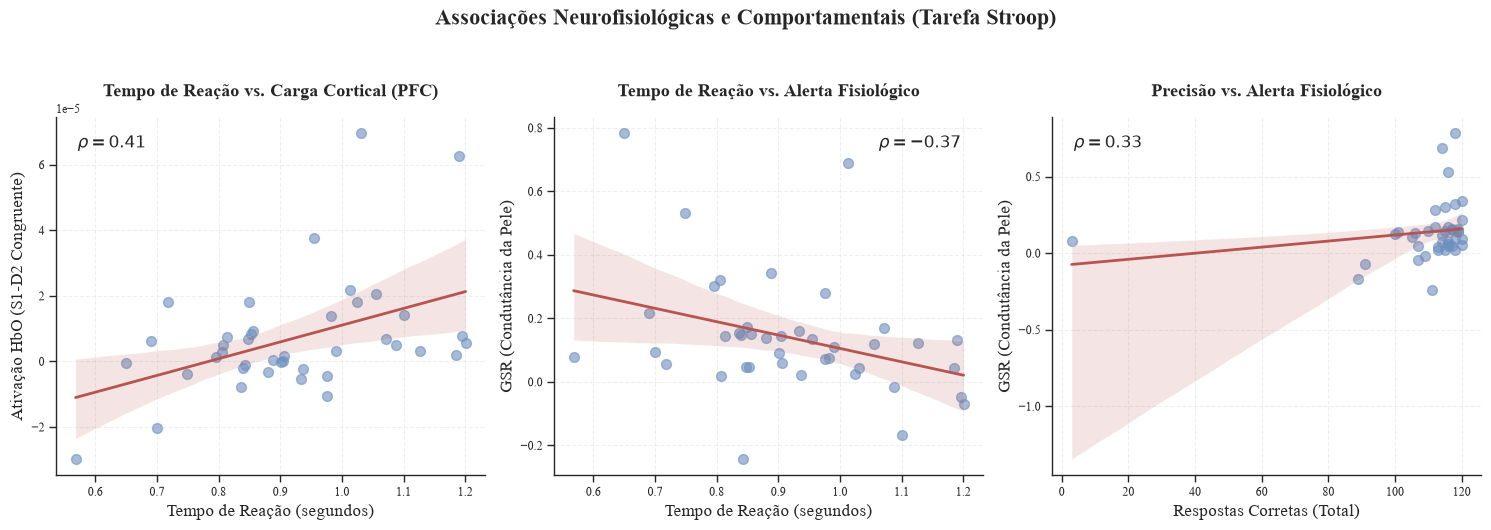

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Configurar a fonte global para Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura de Dados (Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"
caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx

pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5:  
        df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Amostra Analítica e Merge (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

vars_comportamento = ['ID_Clean', 'ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_stroop, on='ID_Clean', how='inner')

# Forçar numéricos nas variáveis alvo para o Top 3
variaveis_alvo = ['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg', 'HbO_S1_D2_Con_Beta', 'GSR_Media_Con']

for var in variaveis_alvo:
    if var in df_master.columns:
        if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
            df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=variaveis_alvo)

# ==========================================================
# 3. Desenho dos Gráficos de Dispersão (Scatter Plots)
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Associações Neurofisiológicas e Comportamentais (Tarefa Stroop)", fontsize=16, fontweight='bold', y=1.05)

# Paleta baseada nas tuas cores anteriores, usando um azul académico
cor_pontos = '#6c8ebf' 
cor_linha = '#b85450'

# PLOT 1: Tempo de Reação vs HbO_S1_D2
sns.regplot(
    data=df_master, x='ST_RT_Medio_Total_seg', y='HbO_S1_D2_Con_Beta',
    ax=axes[0], scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[0].set_title("Tempo de Reação vs. Carga Cortical (PFC)", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Tempo de Reação (segundos)", fontsize=12)
axes[0].set_ylabel("Ativação HbO (S1-D2 Congruente)", fontsize=12)
axes[0].text(0.05, 0.95, r'$\rho = 0.41$', transform=axes[0].transAxes, fontsize=12, fontweight='bold', va='top')

# PLOT 2: Tempo de Reação vs GSR
sns.regplot(
    data=df_master, x='ST_RT_Medio_Total_seg', y='GSR_Media_Con',
    ax=axes[1], scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[1].set_title("Tempo de Reação vs. Alerta Fisiológico", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Tempo de Reação (segundos)", fontsize=12)
axes[1].set_ylabel("GSR (Condutância da Pele)", fontsize=12)
axes[1].text(0.95, 0.95, r'$\rho = -0.37$', transform=axes[1].transAxes, fontsize=12, fontweight='bold', ha='right', va='top')

# PLOT 3: Precisão vs GSR
sns.regplot(
    data=df_master, x='ST_Acc_N_Total', y='GSR_Media_Con',
    ax=axes[2], scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[2].set_title("Precisão vs. Alerta Fisiológico", fontsize=13, fontweight='bold', pad=15)
axes[2].set_xlabel("Respostas Corretas (Total)", fontsize=12)
axes[2].set_ylabel("GSR (Condutância da Pele)", fontsize=12)
axes[2].text(0.05, 0.95, r'$\rho = 0.33$', transform=axes[2].transAxes, fontsize=12, fontweight='bold', va='top')

# Ajustes finais e limpeza visual
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

# Exportar
caminho_figura = pasta_resultados / "ScatterPlots_Stroop.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Gráficos exportados com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 10b: Visualização de Correlações Cérebro-Comportamento (Decision Making)

Em contraste com a tarefa de Stroop, a exploração visual da tarefa de *Decision Making* foca-se nas três associações de maior magnitude detetadas na matriz, ilustrando a ausência de predição linear forte entre a atividade pré-frontal/periférica e o desempenho nesta tarefa específica.

**Estratégia Visual:**
* Identificação automática do "Top 3" de correlações (maior *Rho* absoluto) no relatório gerado na Fase 9b.
* Construção de *Scatter Plots* com linha de regressão e sombreamento do intervalo de confiança (95% CI).
* Formatação académica (Times New Roman, 300 DPI) emparelhada com o design da Fase 10.

A carregar matriz de correlações e a isolar o Top 3 do Decision Making...

Gráficos exportados com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\ScatterPlots_DecisionMaking.png


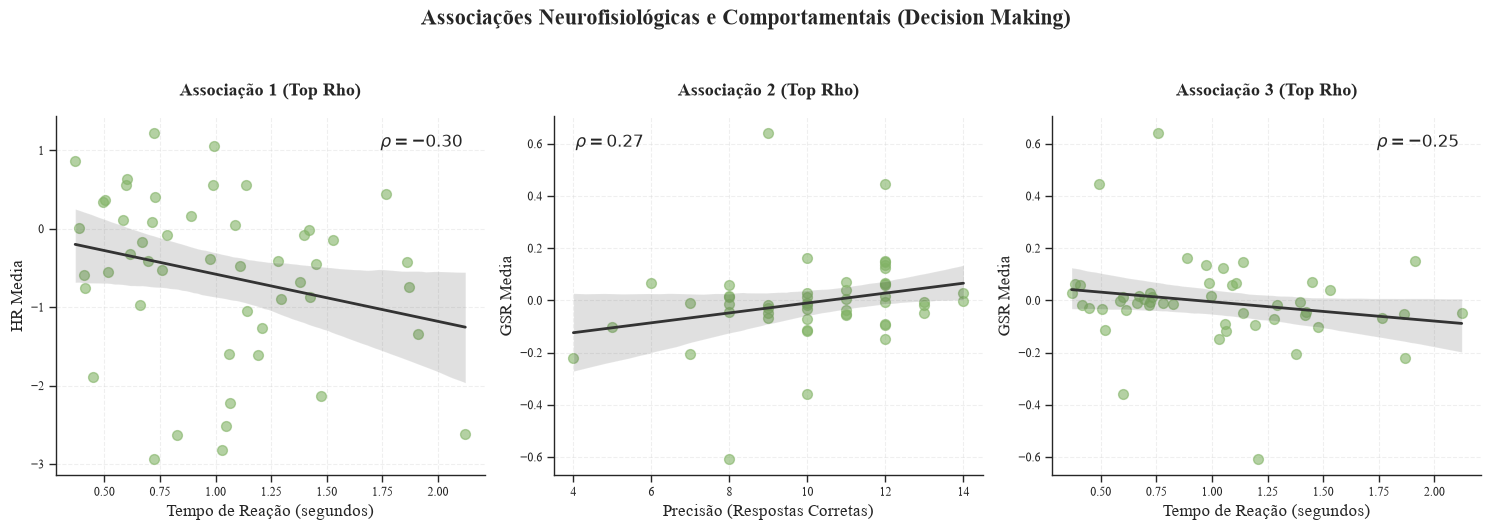

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Configurar a fonte global
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura do Top 3 de Correlações (DM)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"

caminho_corr = pasta_resultados / "Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx"

print("A carregar matriz de correlações e a isolar o Top 3 do Decision Making...")
df_corr = pd.read_excel(caminho_corr)

# Encontrar as 3 correlações mais fortes (em valor absoluto)
df_corr['Abs_Rho'] = df_corr['Rho (Spearman)'].abs()
top3 = df_corr.sort_values(by='Abs_Rho', ascending=False).head(3).reset_index(drop=True)

# Guardar os pares (Comportamento, Neurofisiologia) e os seus Rhos
pares_plot = []
for i, row in top3.iterrows():
    pares_plot.append({
        'X': row['Variável_Comportamental'],
        'Y': row['Variável_Neurofisiológica'],
        'Rho': row['Rho (Spearman)']
    })

# ==========================================================
# 2. Reconstruir a Amostra Analítica (Merge DM)
# ==========================================================
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# Limpeza e Filtro N=51
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

vars_comportamento = ['ID_Clean', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_dm, on='ID_Clean', how='inner')

# Forçar tipo numérico estrito para as variáveis alvo que vão ser desenhadas
vars_para_limpar = [p['X'] for p in pares_plot] + [p['Y'] for p in pares_plot]
for var in set(vars_para_limpar):
    if var in df_master.columns:
        if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
            df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=list(set(vars_para_limpar)))

# ==========================================================
# 3. Desenho dos Gráficos de Dispersão Dinâmicos
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Associações Neurofisiológicas e Comportamentais (Decision Making)", fontsize=16, fontweight='bold', y=1.05)

# Paleta (cores contrastantes ou idênticas ao Stroop para uniformidade na tese)
cor_pontos = '#82b366' # Um tom esverdeado subtil para distinguir do Stroop
cor_linha = '#333333'

for i, par in enumerate(pares_plot):
    ax = axes[i]
    x_var = par['X']
    y_var = par['Y']
    rho_val = par['Rho']
    
    sns.regplot(
        data=df_master, x=x_var, y=y_var,
        ax=ax, scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
    )
    
    # Nomes dos eixos mais legíveis (traduzir as labels comportamentais)
    xlabel = "Tempo de Reação (segundos)" if "RT" in x_var else "Precisão (Respostas Corretas)"
    ylabel = y_var.replace("_Beta", "").replace("_", " ") # Limpar um pouco o nome do fNIRS/GSR
    
    ax.set_title(f"Associação {i+1} (Top Rho)", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    
    # Colocar o Rho no canto do gráfico (canto superior esquerdo ou direito consoante a tendência)
    x_pos = 0.05 if rho_val >= 0 else 0.95
    ha_align = 'left' if rho_val >= 0 else 'right'
    ax.text(x_pos, 0.95, f'$\\rho = {rho_val:.2f}$', transform=ax.transAxes, fontsize=12, fontweight='bold', ha=ha_align, va='top')

# Limpeza visual
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

# Exportar
caminho_figura = pasta_resultados / "ScatterPlots_DecisionMaking.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"\nGráficos exportados com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 10c: Visualização de Correlações Corticais (Decision Making)

Exploração visual focada especificamente nos marcadores hemodinâmicos corticais (fNIRS) durante a tarefa de Tomada de Decisão.
O objetivo é ilustrar o contraste de recrutamento pré-frontal em comparação com a tarefa de Stroop, mapeando a correlação cortical (HbO) mais elevada extraída da matriz.

Top Cortical RT: HbO_S5_D6_Beta (rho = 0.1377)
Top Cortical Acc: HbO_S2_D3_Beta (rho = 0.172)

Gráficos corticais exportados com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\ScatterPlots_Cortical_DecisionMaking.png


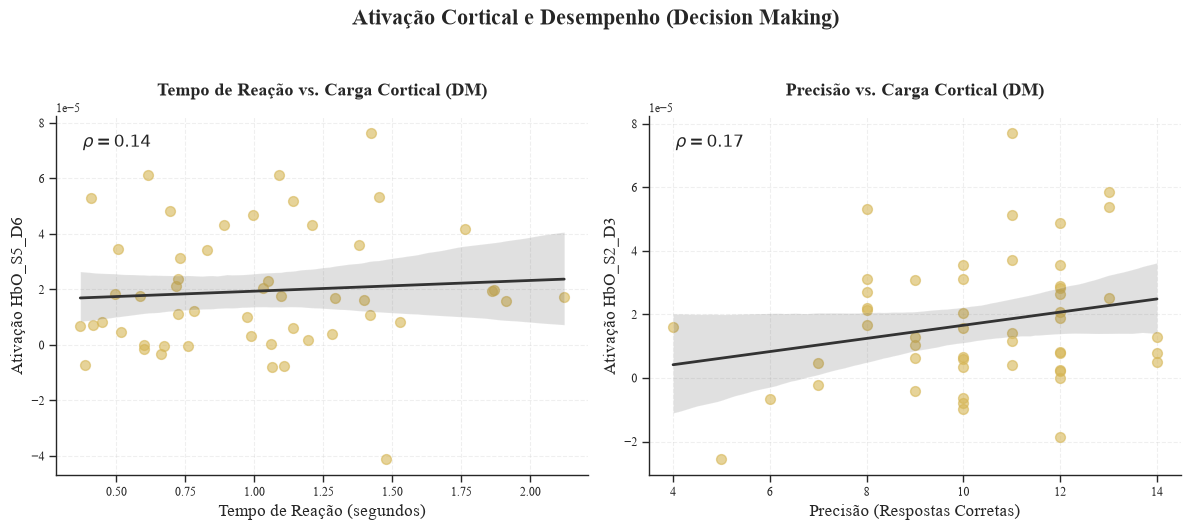

In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Isolar o Melhor Preditivo Cortical (HbO) do DM
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
caminho_corr = pasta_resultados / "Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx"

df_corr = pd.read_excel(caminho_corr)

# Filtrar APENAS variáveis fNIRS (que comecem por HbO)
df_corr_cortical = df_corr[df_corr['Variável_Neurofisiológica'].str.startswith('HbO')].copy()
df_corr_cortical['Abs_Rho'] = df_corr_cortical['Rho (Spearman)'].abs()

# Extrair a melhor para o Tempo de Reação e a melhor para a Precisão
top_rt = df_corr_cortical[df_corr_cortical['Comportamento'] == 'Tempo de Reação (RT)'].sort_values(by='Abs_Rho', ascending=False).iloc[0]
top_acc = df_corr_cortical[df_corr_cortical['Comportamento'] == 'Precisão (Acc_N)'].sort_values(by='Abs_Rho', ascending=False).iloc[0]

pares_plot = [
    {'X': top_rt['Variável_Comportamental'], 'Y': top_rt['Variável_Neurofisiológica'], 'Rho': top_rt['Rho (Spearman)'], 'Title': 'Tempo de Reação vs. Carga Cortical (DM)'},
    {'X': top_acc['Variável_Comportamental'], 'Y': top_acc['Variável_Neurofisiológica'], 'Rho': top_acc['Rho (Spearman)'], 'Title': 'Precisão vs. Carga Cortical (DM)'}
]

print(f"Top Cortical RT: {top_rt['Variável_Neurofisiológica']} (rho = {top_rt['Rho (Spearman)']})")
print(f"Top Cortical Acc: {top_acc['Variável_Neurofisiológica']} (rho = {top_acc['Rho (Spearman)']})")

# ==========================================================
# 2. Reconstruir a Amostra Analítica (Merge DM)
# ==========================================================
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset" if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names else 0)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

vars_comportamento = ['ID_Clean', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_dm, on='ID_Clean', how='inner')

vars_para_limpar = [p['X'] for p in pares_plot] + [p['Y'] for p in pares_plot]
for var in set(vars_para_limpar):
    if var in df_master.columns:
        if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
            df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=list(set(vars_para_limpar)))

# ==========================================================
# 3. Desenho dos Gráficos Corticais
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Ativação Cortical e Desempenho (Decision Making)", fontsize=16, fontweight='bold', y=1.05)

cor_pontos = '#d6b656' # Tom mostarda/dourado para contrastar subtilmente com os outros
cor_linha = '#333333'

for i, par in enumerate(pares_plot):
    ax = axes[i]
    x_var = par['X']
    y_var = par['Y']
    rho_val = par['Rho']
    
    sns.regplot(
        data=df_master, x=x_var, y=y_var,
        ax=ax, scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
    )
    
    xlabel = "Tempo de Reação (segundos)" if "RT" in x_var else "Precisão (Respostas Corretas)"
    ylabel = f"Ativação {y_var.replace('_Beta', '')}"
    
    ax.set_title(par['Title'], fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    
    x_pos = 0.05 if rho_val >= 0 else 0.95
    ha_align = 'left' if rho_val >= 0 else 'right'
    ax.text(x_pos, 0.95, f'$\\rho = {rho_val:.2f}$', transform=ax.transAxes, fontsize=12, fontweight='bold', ha=ha_align, va='top')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

caminho_figura = pasta_resultados / "ScatterPlots_Cortical_DecisionMaking.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"\nGráficos corticais exportados com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 11: Visualização Científica (Heatmaps Corticais)

Geração de mapas de calor (Heatmaps) para ilustrar a magnitude da ativação cortical (HbO) em cada canal fNIRS, estratificada por grupo (Atletas, Futebolistas, Não-Federados).

**Estratégia Visual:**
* Extração dos coeficientes Beta (HbO) médios de cada canal para cada subgrupo da amostra.
* Construção de uma matriz térmica divergente (azul = desativação/eficiência; vermelho = recrutamento/esforço).
* Esta visualização suporta a Discussão sobre a *Neural Efficiency Hypothesis*, ilustrando diferenças globais de recrutamento pré-frontal.

Heatmap Cortical exportado com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Heatmap_Cortical_Stroop.png


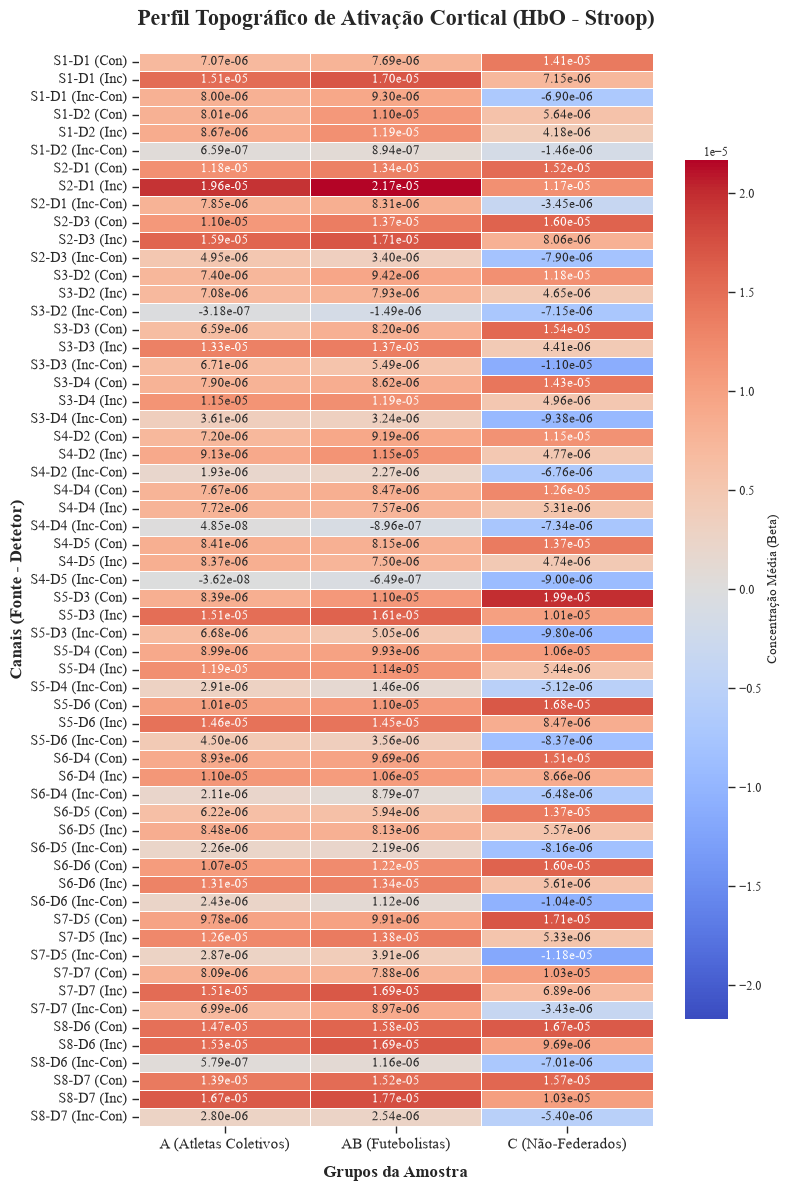

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura (Foco no Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"
caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5: df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Definição da Amostra Analítica (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C (Não-Federados)'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A (Atletas Coletivos)'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A (Atletas Coletivos)') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB (Futebolistas)'

df_mapeamento = pd.concat([df_analitica[['ID_Clean', 'Grupo_Análise']], df_fut[['ID_Clean', 'Grupo_Análise']]], ignore_index=True)
df_master = pd.merge(df_mapeamento, df_stroop, on='ID_Clean', how='inner')

# ==========================================================
# 3. Processamento dos Canais fNIRS para a Matriz
# ==========================================================
# Extrair apenas colunas de HbO
canais_hbo = [col for col in df_master.columns if col.startswith('HbO_') and col.endswith('_Beta')]

for col in canais_hbo:
    if df_master[col].dtype == 'object' or df_master[col].dtype == 'string':
        df_master[col] = df_master[col].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

# Calcular a média de ativação por grupo
df_medias = df_master.groupby('Grupo_Análise')[canais_hbo].mean().T

# Limpar o nome das linhas (canais) para ficar académico (ex: S1-D2 Incongruente)
novos_nomes = []
for nome in df_medias.index:
    partes = nome.split('_')
    # Ex: HbO_S1_D1_Inc_Beta -> 'S1-D1 (Inc)'
    # Lidar com diferenças de nomenclatura
    s_d = f"{partes[1]}-{partes[2]}"
    cond = partes[3] if len(partes) > 3 else ""
    novos_nomes.append(f"{s_d} ({cond})")

df_medias.index = novos_nomes

# Ordenar a matriz alfabeticamente pelos canais
df_medias = df_medias.sort_index()

# ==========================================================
# 4. Desenho do Heatmap
# ==========================================================
fig, ax = plt.subplots(figsize=(8, 12)) # Formato vertical (A4 friendly)

# Encontrar o valor máximo absoluto para centrar a paleta a zero perfeitamente
vmax = np.nanmax(np.abs(df_medias.values))
vmin = -vmax

# Heatmap com paleta divergente 'coolwarm' (padrão MNE-NIRS para neuroimagem)
sns.heatmap(df_medias, cmap='coolwarm', center=0, vmin=vmin, vmax=vmax, 
            annot=True, fmt=".2e", annot_kws={"size": 9, "family": "Times New Roman"},
            cbar_kws={'label': 'Concentração Média (Beta)', 'shrink': 0.8},
            linewidths=.5, ax=ax)

ax.set_title('Perfil Topográfico de Ativação Cortical (HbO - Stroop)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Grupos da Amostra', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Canais (Fonte - Detetor)', fontsize=12, fontweight='bold')

plt.xticks(fontsize=11, rotation=0)
plt.yticks(fontsize=10)

plt.tight_layout()

caminho_figura = pasta_resultados / "Heatmap_Cortical_Stroop.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Heatmap Cortical exportado com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 11b: Visualização Científica (Heatmap Cortical - Decision Making)

Geração do mapa de calor topográfico da ativação cortical (HbO) para a tarefa de Tomada de Decisão (*Decision Making*), estratificado pelos grupos da amostra (*Atletas Coletivos, Futebolistas, Não-Federados*).

**Objetivo Analítico:**
* Mapear a distribuição espacial da ativação no Córtex Pré-Frontal durante o processo de tomada de decisão desportiva/cognitiva.
* Fornecer a contrapartida visual ao heatmap do Stroop, permitindo evidenciar se a ausência de correlações fortes na Fase 10b se reflete também numa ativação cortical mais atenuada, distribuída ou homogénea entre os grupos.

Heatmap Cortical (Decision Making) exportado com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Heatmap_Cortical_DecisionMaking.png


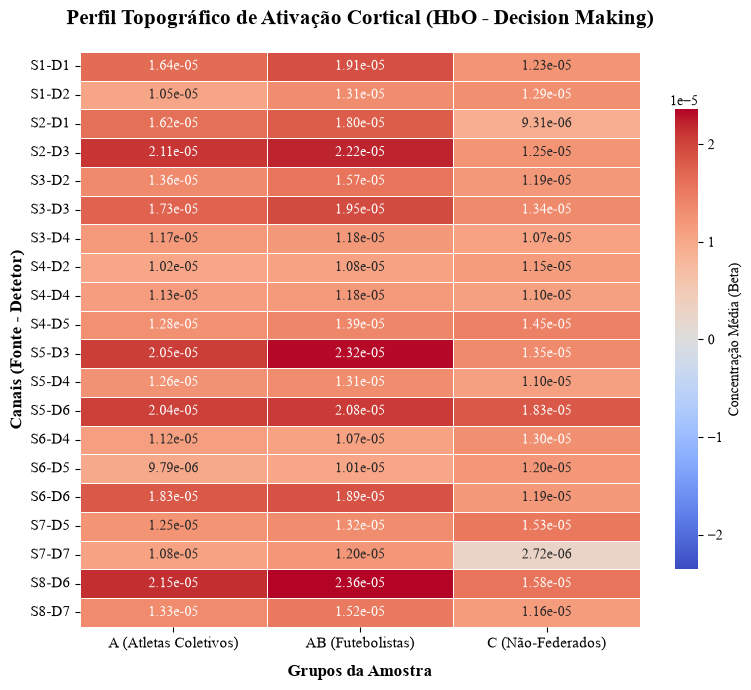

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura (Decision Making)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# ==========================================================
# 2. Definição da Amostra Analítica (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C (Não-Federados)'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A (Atletas Coletivos)'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A (Atletas Coletivos)') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB (Futebolistas)'

df_mapeamento = pd.concat([df_analitica[['ID_Clean', 'Grupo_Análise']], df_fut[['ID_Clean', 'Grupo_Análise']]], ignore_index=True)
df_master = pd.merge(df_mapeamento, df_dm, on='ID_Clean', how='inner')

# ==========================================================
# 3. Processamento dos Canais fNIRS para a Matriz (DM)
# ==========================================================
canais_hbo = [col for col in df_master.columns if col.startswith('HbO_') and col.endswith('_Beta')]

for col in canais_hbo:
    if df_master[col].dtype == 'object' or df_master[col].dtype == 'string':
        df_master[col] = df_master[col].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_medias = df_master.groupby('Grupo_Análise')[canais_hbo].mean().T

# Limpeza robusta do nome dos canais (ex: S1-D2, ignorando o "Beta")
novos_nomes = []
for nome in df_medias.index:
    partes = nome.split('_')
    s_d = f"{partes[1]}-{partes[2]}"
    
    # Se houver uma condição escrita no meio (ex: HbO_S1_D1_Cond1_Beta)
    if len(partes) > 4 and partes[-1].lower() == 'beta':
        cond = "_".join(partes[3:-1])
        novos_nomes.append(f"{s_d} ({cond})")
    elif len(partes) > 3 and partes[3].lower() != 'beta':
        cond = partes[3]
        novos_nomes.append(f"{s_d} ({cond})")
    else:
        novos_nomes.append(s_d)

df_medias.index = novos_nomes
df_medias = df_medias.sort_index()

# ==========================================================
# 4. Desenho do Heatmap
# ==========================================================
# Ajustar a altura da figura dinamicamente com base no número de canais exportados no DM
altura_fig = max(5, len(df_medias) * 0.35)
fig, ax = plt.subplots(figsize=(8, altura_fig)) 

vmax = np.nanmax(np.abs(df_medias.values))
if vmax == 0 or np.isnan(vmax): 
    vmax = 1e-5
vmin = -vmax

sns.heatmap(df_medias, cmap='coolwarm', center=0, vmin=vmin, vmax=vmax, 
            annot=True, fmt=".2e", annot_kws={"size": 10, "family": "Times New Roman"},
            cbar_kws={'label': 'Concentração Média (Beta)', 'shrink': 0.8},
            linewidths=.5, ax=ax)

ax.set_title('Perfil Topográfico de Ativação Cortical (HbO - Decision Making)', fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel('Grupos da Amostra', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Canais (Fonte - Detetor)', fontsize=12, fontweight='bold')

plt.xticks(fontsize=11, rotation=0)
plt.yticks(fontsize=11)

plt.tight_layout()

caminho_figura = pasta_resultados / "Heatmap_Cortical_DecisionMaking.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Heatmap Cortical (Decision Making) exportado com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fases 9–10: Correlações cérebro–comportamento e visualização

## Objetivo

Explorar associações entre o desempenho comportamental nas tarefas Stroop
e Decision Making e os marcadores neurofisiológicos de fNIRS e fisiologia
periférica.

Estas análises são exploratórias e complementares às comparações entre grupos;
não constituem uma alternativa confirmatória escolhida em função da ausência
de significância nas análises anteriores.

## Estratégia analítica

- Integração das bases comportamental e neurofisiológica através do ID.
- Exclusão dos participantes atualmente federados em modalidades individuais,
  mantendo o critério utilizado nas análises anteriores.
- Manutenção, em cada tarefa, dos participantes com os dois indicadores
  comportamentais disponíveis: acertos totais e tempo de reação médio.
- Cálculo de correlações de Spearman bilaterais, com exclusão de valores
  omissos separadamente para cada par comportamento–neurofisiologia.
- Aplicação de Holm–Bonferroni para controlo do erro familiar (FWER),
  separadamente por tarefa e dimensão comportamental.
- Exportação do N efetivo, coeficiente de Spearman, p bruto e p corrigido
  de cada associação, sem arredondamento dos valores armazenados.
- Exportação de uma auditoria dos participantes incluídos e excluídos.

A amostra efetiva é determinada pelos dados e pode variar entre tarefas e
entre marcadores; não se pressupõe N = 51 para todas as correlações.

## Visualização

Os gráficos utilizam exatamente os mesmos pares válidos da matriz.
Cada painel apresenta o N, o coeficiente de Spearman, o p bruto e o p-Holm
da associação correspondente.

São representados:

1. Stroop: os três pares previamente selecionados para visualização.
2. Decision Making: as três associações de maior magnitude absoluta.
3. Decision Making cortical: a associação HbO de maior magnitude absoluta
   para cada dimensão comportamental.

Os gráficos de dispersão apresentam os valores originais, sem reta de
regressão linear, evitando confundir um ajuste linear com a correlação
de Spearman calculada sobre postos.

A seleção das associações de maior magnitude é descritiva e exploratória.
A magnitude do coeficiente, isoladamente, não demonstra significância,
capacidade preditiva ou eficiência neural. A interpretação inferencial
considera o p corrigido por Holm.

Stroop: 50 participantes na base analítica.
  68 marcadores; 0 associações significativas após Holm.
DecisionMaking: 51 participantes na base analítica.
  24 marcadores; 0 associações significativas após Holm.
Figura guardada: ScatterPlots_Stroop.png


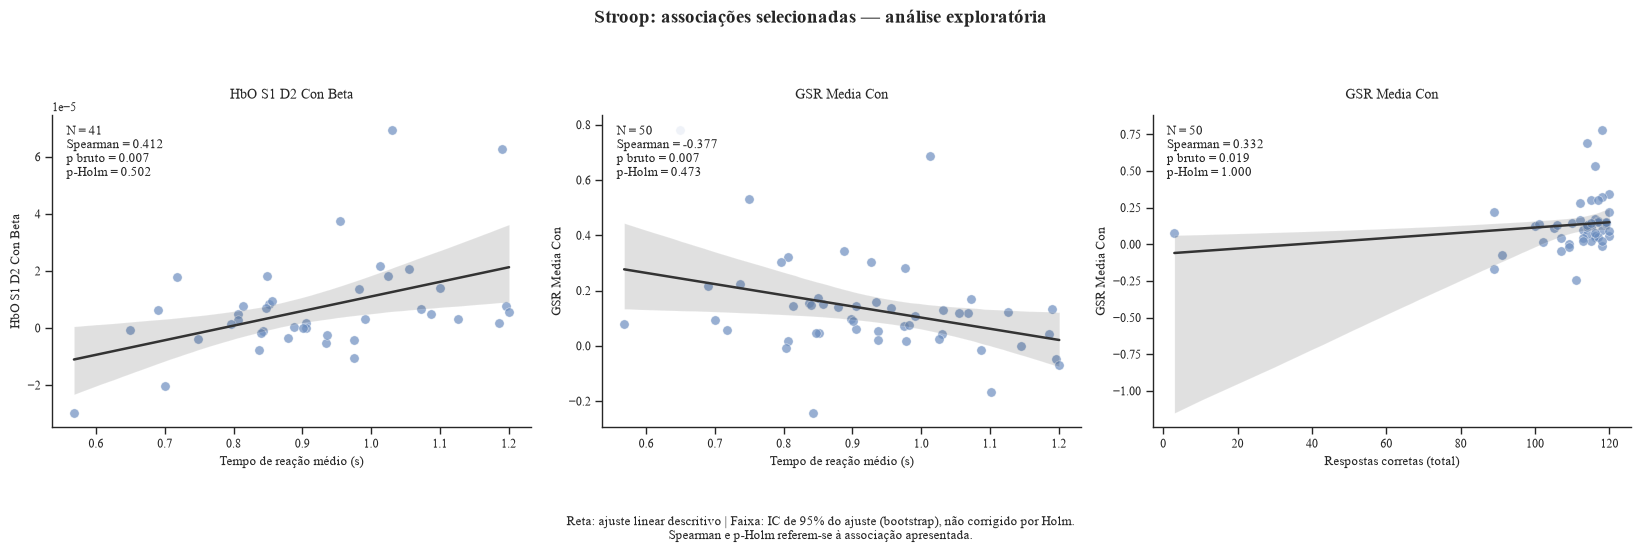

Figura guardada: ScatterPlots_DecisionMaking.png


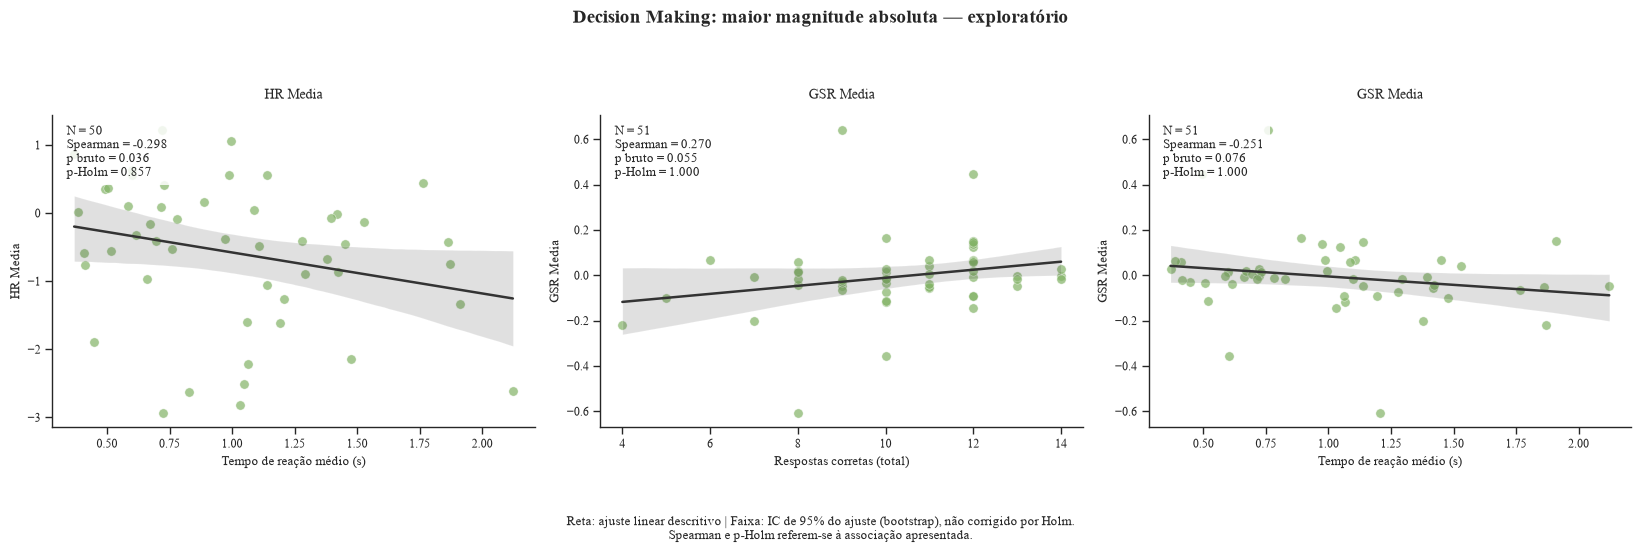

Figura guardada: ScatterPlots_Cortical_DecisionMaking.png


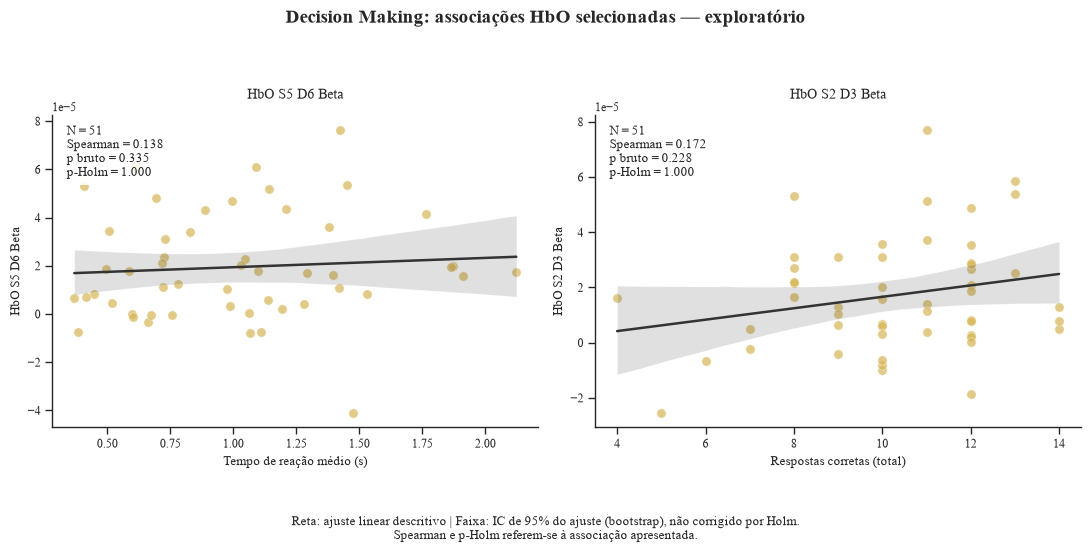


Stroop: HR × comportamento


,Variável_Comportamental,Variável_Neurofisiológica,n,Rho (Spearman),p-unc,p-Holm,Significativo
12,ST_Acc_N_Total,HR_Bradicardia_Con,48,0.196463,0.180784,1.0,False
24,ST_Acc_N_Total,HR_Bradicardia_Inc,48,0.160817,0.274864,1.0,False
46,ST_Acc_N_Total,HR_Media_Con,48,0.082286,0.578203,1.0,False
58,ST_Acc_N_Total,HR_Media_Inc,48,0.040272,0.785799,1.0,False
79,ST_RT_Medio_Total_seg,HR_Bradicardia_Inc,48,-0.221559,0.130173,1.0,False
87,ST_RT_Medio_Total_seg,HR_Bradicardia_Con,48,-0.172601,0.240747,1.0,False
98,ST_RT_Medio_Total_seg,HR_Media_Con,48,-0.135801,0.357400,1.0,False
115,ST_RT_Medio_Total_seg,HR_Media_Inc,48,-0.091511,0.536183,1.0,False


Figura guardada: ScatterPlots_HR_Acertos_Stroop.png


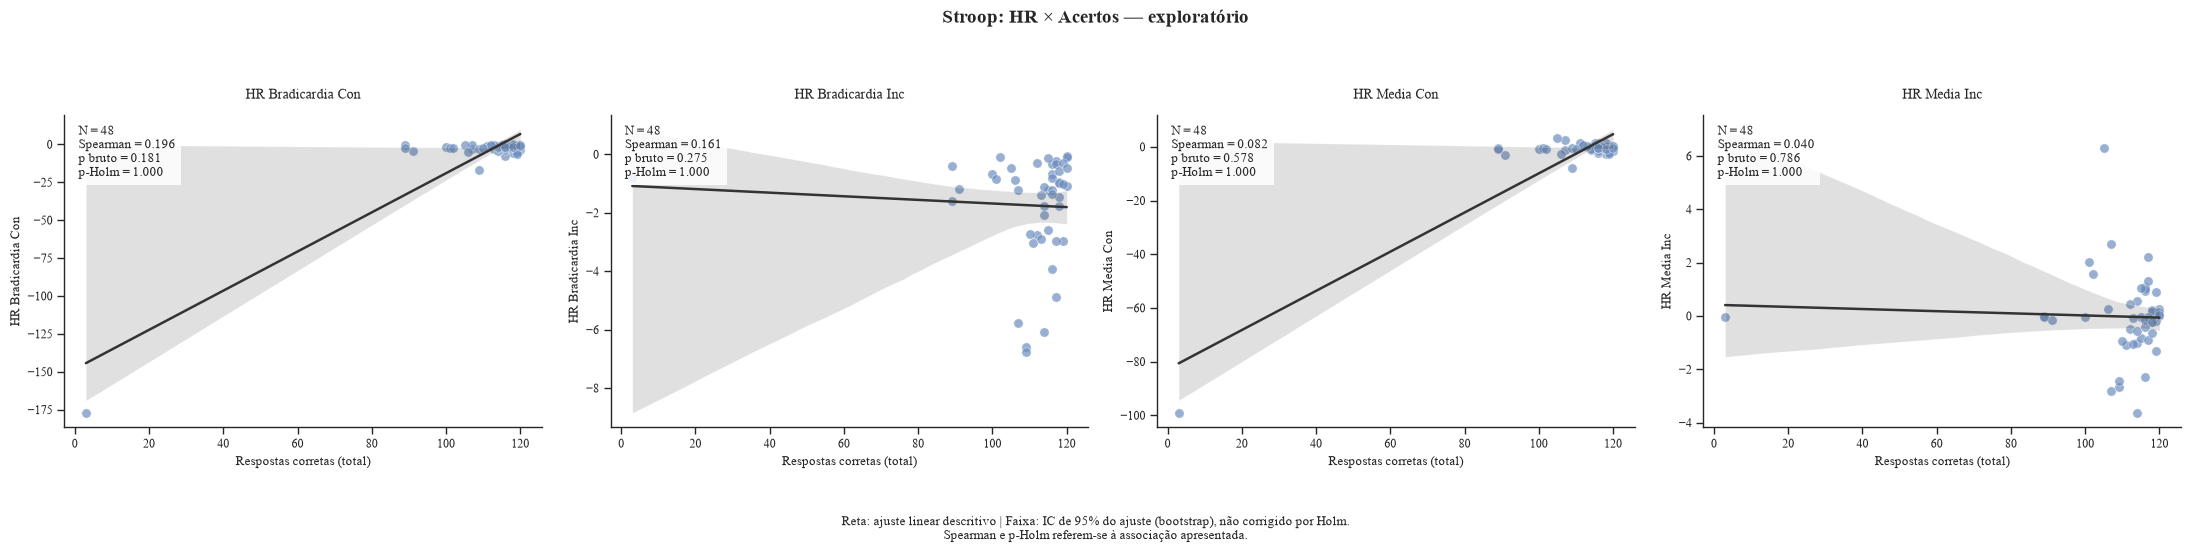

Figura guardada: ScatterPlots_HR_RT_Stroop.png


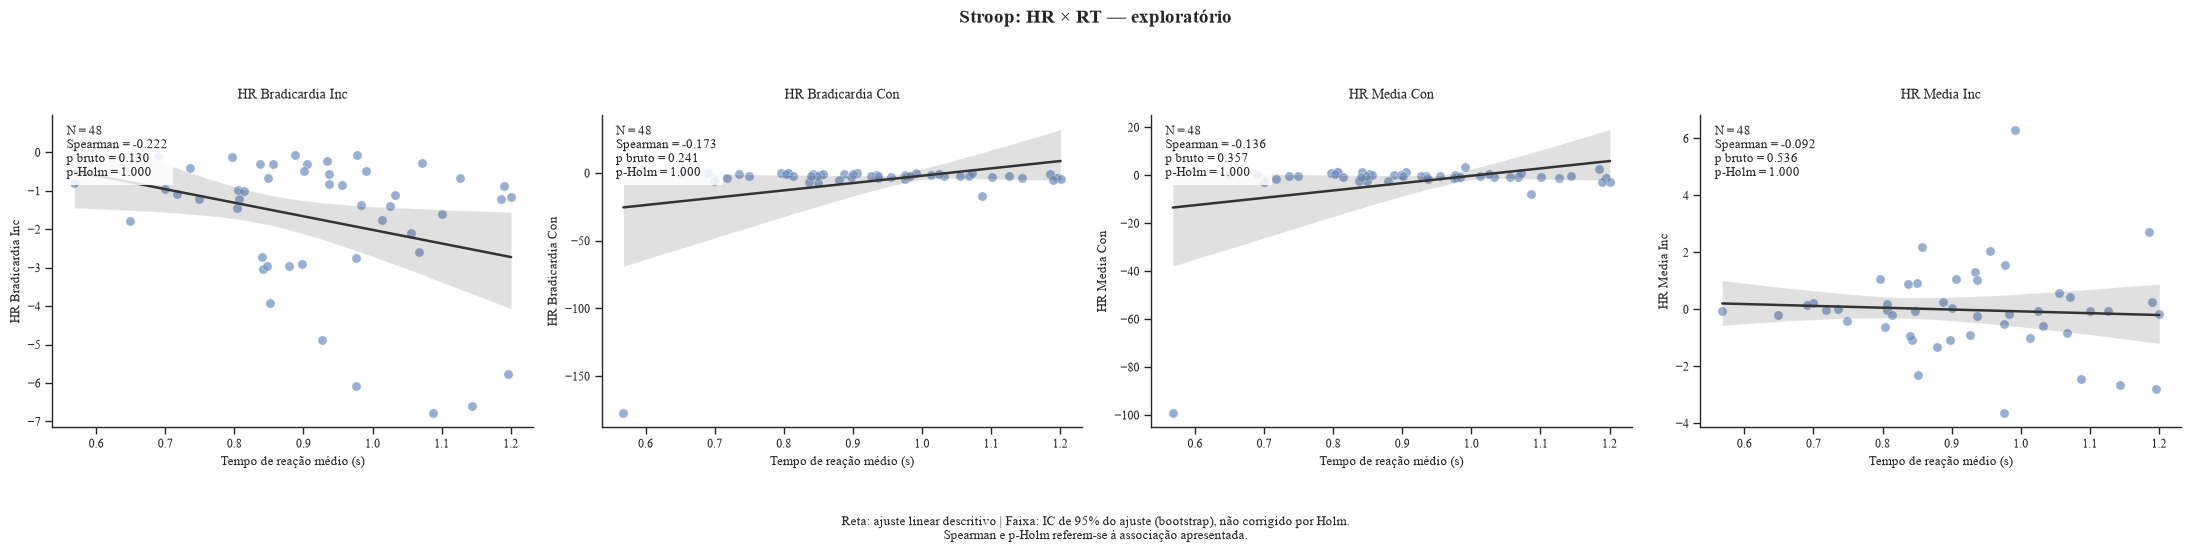


DecisionMaking: HR × comportamento


,Variável_Comportamental,Variável_Neurofisiológica,n,Rho (Spearman),p-unc,p-Holm,Significativo
1,DM_Acc_N_Total,HR_Bradicardia_Max,50,0.194392,0.176140,1.00000,False
8,DM_Acc_N_Total,HR_Media,50,0.088590,0.540677,1.00000,False
24,DM_RT_Medio_Total_seg,HR_Media,50,-0.297767,0.035713,0.85712,False
26,DM_RT_Medio_Total_seg,HR_Bradicardia_Max,50,-0.189916,0.186501,1.00000,False


Figura guardada: ScatterPlots_HR_Acertos_DecisionMaking.png


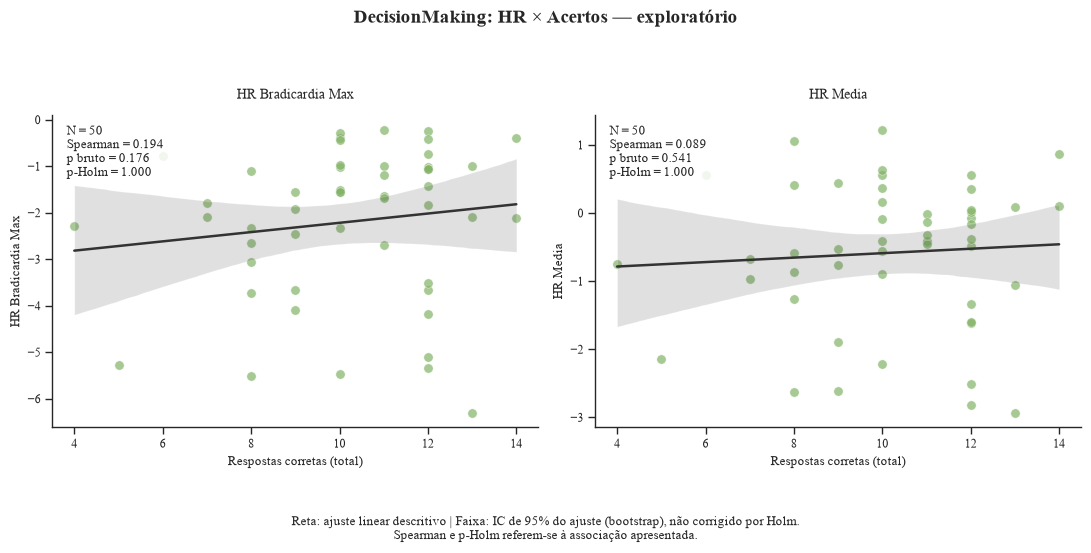

Figura guardada: ScatterPlots_HR_RT_DecisionMaking.png


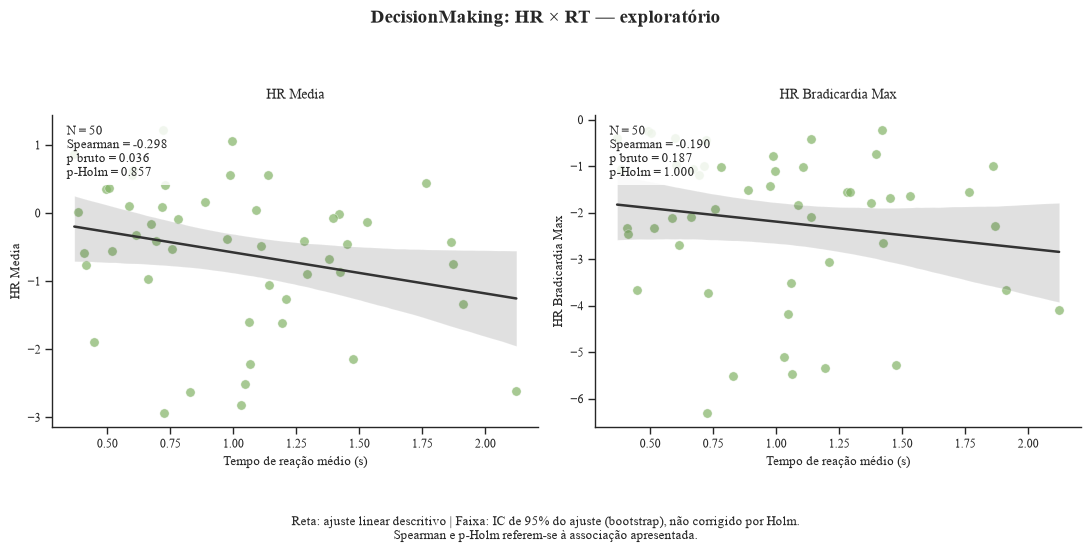


Execução concluída: matrizes, auditorias e gráficos com ajuste linear e IC de 95%.

Resultados guardados em:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Correlacoes_Corrigidas


In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests


# ==========================================================
# 1. Configuração
# ==========================================================
PASTA_DADOS = Path("../data_subjects")
PASTA_SAIDA = (
    PASTA_DADOS
    / "Resultados_Neurofisiologicos"
    / "Correlacoes_Corrigidas"
)
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05

# Configuração visual: ajuste linear e IC bootstrap
IC_PERCENTAGEM = 95
N_BOOTSTRAP = 5000
SEMENTE = 42
COR_LINHA = "#333333"

COL_ESTATUTO = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)
COL_TIPO = (
    "No caso de ser desportista federado, a sua modalidade principal é:"
)

TAREFAS = {
    "Stroop": {
        "base": "dataset_FINAL_SPA_fNIRS_Stroop",
        "acc": "ST_Acc_N_Total",
        "rt": "ST_RT_Medio_Total_seg",
        "cor": "#6c8ebf",
    },
    "DecisionMaking": {
        "base": "dataset_FINAL_SPA_fNIRS_DecisionMaking",
        "acc": "DM_Acc_N_Total",
        "rt": "DM_RT_Medio_Total_seg",
        "cor": "#82b366",
    },
}

sns.set_theme(style="ticks", context="paper")
plt.rcParams["font.family"] = "Times New Roman"


# ==========================================================
# 2. Leitura e validação
# ==========================================================
def limpar_colunas(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()

    if df.columns.duplicated().any():
        raise ValueError("Existem nomes de colunas duplicados.")

    return df


def normalizar_ids(df, nome):
    df = limpar_colunas(df)

    if "ID" not in df.columns:
        raise ValueError(f"{nome}: falta a coluna ID.")

    ids = (
        df["ID"]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\.0$", "", regex=True)
    )

    if (ids.isna() | ids.eq("")).any():
        raise ValueError(f"{nome}: existem IDs vazios.")

    if ids.duplicated().any():
        duplicados = ids[ids.duplicated(keep=False)].tolist()
        raise ValueError(f"{nome}: IDs duplicados: {duplicados}")

    df["ID_Clean"] = ids
    return df


def numerico(serie):
    texto = (
        serie.astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    return pd.to_numeric(texto, errors="coerce").replace(
        [np.inf, -np.inf], np.nan
    )


def ler_fisiologia(nome_base):
    csv = PASTA_DADOS / f"{nome_base}.csv"
    xlsx = PASTA_DADOS / f"{nome_base}.xlsx"

    if csv.exists():
        df = pd.read_csv(csv, sep=";", dtype="string")

        if len(df.columns) < 5:
            df = pd.read_csv(csv, sep=",", dtype="string")

    elif xlsx.exists():
        df = pd.read_excel(xlsx)

    else:
        raise FileNotFoundError(
            f"Não foi encontrado {nome_base}.csv ou .xlsx."
        )

    return normalizar_ids(df, nome_base)


caminho_demo = PASTA_DADOS / "Merge_Dataset_Study_2.xlsx"

with pd.ExcelFile(caminho_demo) as livro:
    folha = "Merge Dataset" if "Merge Dataset" in livro.sheet_names else 0
    df_demo = pd.read_excel(livro, sheet_name=folha)

df_demo = normalizar_ids(df_demo, "Base comportamental")

if COL_ESTATUTO not in df_demo.columns:
    raise ValueError(f"Falta a coluna: {COL_ESTATUTO}")

estatuto = (
    df_demo[COL_ESTATUTO]
    .astype("string")
    .str.strip()
    .str.casefold()
)

if not estatuto.isin(["sim", "não", "nao"]).all():
    raise ValueError(
        "Existem estatutos desportivos vazios ou não reconhecidos."
    )

if COL_TIPO in df_demo.columns:
    tipo = (
        df_demo[COL_TIPO]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    tipo_valido = tipo.str.contains(
        "individual|coletiva", regex=True, na=False
    )

    if ((estatuto == "sim") & ~tipo_valido).any():
        raise ValueError(
            "Existem federados sem classificação válida da modalidade."
        )

    is_individual = tipo.str.contains(
        "individual", regex=False, na=False
    )

else:
    if "Indique a modalidade principal" not in df_demo.columns:
        raise ValueError("Falta a informação da modalidade principal.")

    modalidade = (
        df_demo["Indique a modalidade principal"]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    if (
        (estatuto == "sim")
        & (modalidade.isna() | modalidade.eq(""))
    ).any():
        raise ValueError("Existem federados sem modalidade indicada.")

    coletivas = [
        "futebol",
        "futsal",
        "andebol",
        "voleibol",
        "basquetebol",
    ]

    is_individual = ~modalidade.isin(coletivas)

excluir_individuais = (estatuto == "sim") & is_individual


# ==========================================================
# 3. Amostra comum e auditoria por ID
# ==========================================================
def preparar_tarefa(tarefa, config):
    fisiologia = ler_fisiologia(config["base"])
    comportamentais = [config["acc"], config["rt"]]

    for coluna in comportamentais:
        if coluna not in df_demo.columns:
            raise ValueError(f"{tarefa}: falta {coluna}.")

    neuro = [
        coluna
        for coluna in fisiologia.columns
        if (
            coluna.startswith(("GSR_", "HR_"))
            or (
                coluna.startswith("HbO_")
                and coluna.endswith("_Beta")
            )
        )
    ]

    if not neuro:
        raise ValueError(f"{tarefa}: não foram encontrados marcadores.")

    comportamento = df_demo[
        ["ID_Clean"] + comportamentais
    ].copy()

    for coluna in comportamentais:
        comportamento[coluna] = numerico(comportamento[coluna])

    for coluna in neuro:
        fisiologia[coluna] = numerico(fisiologia[coluna])

    auditoria = comportamento.copy()

    auditoria["Excluido_individual"] = (
        excluir_individuais.to_numpy()
    )

    auditoria["Presente_fisiologia"] = (
        auditoria["ID_Clean"].isin(fisiologia["ID_Clean"])
    )

    auditoria["Comportamento_completo"] = (
        auditoria[comportamentais].notna().all(axis=1)
    )

    auditoria["Incluido_base_analitica"] = (
        ~auditoria["Excluido_individual"]
        & auditoria["Presente_fisiologia"]
        & auditoria["Comportamento_completo"]
    )

    ids_incluidos = auditoria.loc[
        auditoria["Incluido_base_analitica"], "ID_Clean"
    ]

    master = comportamento.loc[
        comportamento["ID_Clean"].isin(ids_incluidos)
    ].merge(
        fisiologia[["ID_Clean"] + neuro],
        on="ID_Clean",
        how="inner",
        validate="one_to_one",
    )

    ids_so_fisiologia = fisiologia.loc[
        ~fisiologia["ID_Clean"].isin(df_demo["ID_Clean"]),
        ["ID_Clean"],
    ]

    with pd.ExcelWriter(
        PASTA_SAIDA / f"Auditoria_Amostra_{tarefa}.xlsx"
    ) as writer:
        auditoria.to_excel(
            writer,
            sheet_name="Auditoria_ID",
            index=False,
        )
        ids_so_fisiologia.to_excel(
            writer,
            sheet_name="IDs_so_fisiologia",
            index=False,
        )
        master.to_excel(
            writer,
            sheet_name="Base_analitica",
            index=False,
        )

    print(f"{tarefa}: {len(master)} participantes na base analítica.")

    return master, neuro


# ==========================================================
# 4. Correlações por par e Holm por dimensão
# ==========================================================
def dados_do_par(master, x, y):
    return master[
        ["ID_Clean", x, y]
    ].dropna(subset=[x, y]).copy()


def calcular_matriz(master, neuro, config):
    linhas = []

    for x, dimensao in [
        (config["acc"], "Precisão (Acc_N)"),
        (config["rt"], "Tempo de Reação (RT)"),
    ]:
        for y in neuro:
            dados = dados_do_par(master, x, y)
            n = len(dados)

            valido = (
                n >= 3
                and dados[x].nunique() > 1
                and dados[y].nunique() > 1
            )

            if valido:
                rho, p = spearmanr(
                    dados[x],
                    dados[y],
                    alternative="two-sided",
                )
                estado = "Calculada"

            else:
                rho, p = np.nan, np.nan
                estado = "N insuficiente ou variável constante"

            linhas.append({
                "Variável_Comportamental": x,
                "Variável_Neurofisiológica": y,
                "n": n,
                "Rho (Spearman)": rho,
                "p-unc": p,
                "Comportamento": dimensao,
                "Estado": estado,
            })

    corr = pd.DataFrame(linhas)
    corr["p-Holm"] = np.nan
    corr["Significativo"] = False
    corr["N_testes_familia"] = 0

    for dimensao in corr["Comportamento"].unique():
        familia = corr["Comportamento"].eq(dimensao)
        validos = familia & corr["p-unc"].notna()

        m = int(validos.sum())
        corr.loc[familia, "N_testes_familia"] = m

        if m:
            rejeitar, p_corrigido, _, _ = multipletests(
                corr.loc[validos, "p-unc"].to_numpy(),
                alpha=ALPHA,
                method="holm",
            )

            corr.loc[validos, "p-Holm"] = p_corrigido
            corr.loc[validos, "Significativo"] = rejeitar

    corr["Abs_Rho"] = corr["Rho (Spearman)"].abs()

    return corr.sort_values(
        ["Comportamento", "Abs_Rho"],
        ascending=[True, False],
        kind="stable",
    ).reset_index(drop=True)


# ==========================================================
# 5. Gráficos: tendência linear, IC e validação
# ==========================================================
def formatar_p(valor):
    if pd.isna(valor):
        return "= NA"

    return "< 0.001" if valor < 0.001 else f"= {valor:.3f}"


def desenhar_paineis(master, corr, pares, titulo, nome, cor):
    if not pares:
        raise ValueError(f"Não existem pares para desenhar: {nome}")

    fig, axes = plt.subplots(
        1,
        len(pares),
        figsize=(5.5 * len(pares), 5.5),
        squeeze=False,
    )
    axes = axes.ravel()

    pontos_exportados = []
    verificacoes = []

    for ax, (x, y) in zip(axes, pares):
        referencia = corr.loc[
            corr["Variável_Comportamental"].eq(x)
            & corr["Variável_Neurofisiológica"].eq(y)
        ]

        if len(referencia) != 1:
            raise ValueError(
                f"Par não encontrado ou duplicado: {x}, {y}"
            )

        linha = referencia.iloc[0]

        if pd.isna(linha["p-unc"]):
            raise ValueError(
                f"Correlação não calculável: {x}, {y}"
            )

        dados = dados_do_par(master, x, y)

        rho, p = spearmanr(
            dados[x],
            dados[y],
            alternative="two-sided",
        )

        consistente = (
            len(dados) == int(linha["n"])
            and np.isclose(
                rho,
                linha["Rho (Spearman)"],
                rtol=0,
                atol=1e-12,
            )
            and np.isclose(
                p,
                linha["p-unc"],
                rtol=0,
                atol=1e-12,
            )
        )

        if not consistente:
            raise AssertionError(
                f"Inconsistência entre matriz e gráfico: {x}, {y}"
            )

        # A faixa usa a cor dos pontos; a reta é cinzenta.
        sns.regplot(
            data=dados,
            x=x,
            y=y,
            ax=ax,
            fit_reg=True,
            ci=IC_PERCENTAGEM,
            n_boot=N_BOOTSTRAP,
            seed=SEMENTE,
            truncate=True,
            color=cor,
            scatter_kws={
                "alpha": 0.70,
                "s": 45,
                "edgecolors": "white",
                "linewidths": 0.4,
            },
            line_kws={
                "color": COR_LINHA,
                "linewidth": 1.8,
            },
        )

        xlabel = (
            "Tempo de reação médio (s)"
            if "_RT_" in x
            else "Respostas corretas (total)"
        )

        ax.set_xlabel(xlabel)
        ax.set_ylabel(y.replace("_", " "))
        ax.set_title(
            y.replace("_", " "),
            fontsize=10,
            pad=12,
        )

        anotacao = (
            f"N = {len(dados)}\n"
            f"Spearman = {rho:.3f}\n"
            f"p bruto {formatar_p(p)}\n"
            f"p-Holm {formatar_p(linha['p-Holm'])}"
        )

        ax.text(
            0.03,
            0.97,
            anotacao,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=9,
            bbox={
                "facecolor": "white",
                "alpha": 0.85,
                "edgecolor": "none",
            },
        )

        sns.despine(ax=ax)

        pontos_exportados.append(pd.DataFrame({
            "ID_Clean": dados["ID_Clean"].to_numpy(),
            "Variável_Comportamental": x,
            "Variável_Neurofisiológica": y,
            "Valor_Comportamental": dados[x].to_numpy(),
            "Valor_Neurofisiologico": dados[y].to_numpy(),
        }))

        verificacoes.append({
            "X": x,
            "Y": y,
            "N_plot": len(dados),
            "Rho_plot": rho,
            "p_plot": p,
            "p-Holm": linha["p-Holm"],
            "Matriz_plot_consistentes": consistente,
            "Ajuste_visual": "Regressão linear",
            "IC_percentagem": IC_PERCENTAGEM,
            "N_bootstrap": N_BOOTSTRAP,
            "Semente": SEMENTE,
        })

    fig.suptitle(
        titulo,
        fontsize=14,
        fontweight="bold",
        y=0.99,
    )

    fig.text(
        0.5,
        0.02,
        (
            "Reta: ajuste linear descritivo | "
            "Faixa: IC de 95% do ajuste (bootstrap), não corrigido por Holm.\n"
            "Spearman e p-Holm referem-se à associação apresentada."
        ),
        ha="center",
        va="bottom",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0.13, 1, 0.93])

    fig.savefig(
        PASTA_SAIDA / f"{nome}.png",
        dpi=300,
        bbox_inches="tight",
    )

    pd.concat(
        pontos_exportados,
        ignore_index=True,
    ).to_csv(
        PASTA_SAIDA / f"{nome}_Dados.csv",
        index=False,
        encoding="utf-8-sig",
    )

    pd.DataFrame(verificacoes).to_csv(
        PASTA_SAIDA / f"{nome}_Validacao.csv",
        index=False,
        encoding="utf-8-sig",
    )

    print(f"Figura guardada: {nome}.png")

    plt.show()
    plt.close(fig)


def extrair_pares(df):
    return list(zip(
        df["Variável_Comportamental"],
        df["Variável_Neurofisiológica"],
    ))


# ==========================================================
# 6. Executar as duas tarefas
# ==========================================================
resultados = {}

for tarefa, config in TAREFAS.items():
    master, neuro = preparar_tarefa(tarefa, config)
    corr = calcular_matriz(master, neuro, config)

    nome_matriz = (
        f"Correlacoes_Cerebro_Comportamento_{tarefa}"
    )

    corr.to_excel(
        PASTA_SAIDA / f"{nome_matriz}.xlsx",
        index=False,
    )

    corr.to_csv(
        PASTA_SAIDA / f"{nome_matriz}.csv",
        index=False,
        encoding="utf-8-sig",
    )

    resultados[tarefa] = {
        "master": master,
        "corr": corr,
    }

    print(
        f"  {len(neuro)} marcadores; "
        f"{int(corr['Significativo'].sum())} associações "
        "significativas após Holm."
    )


# ==========================================================
# 7. Stroop: pares previamente selecionados
# ==========================================================
pares_stroop = [
    ("ST_RT_Medio_Total_seg", "HbO_S1_D2_Con_Beta"),
    ("ST_RT_Medio_Total_seg", "GSR_Media_Con"),
    ("ST_Acc_N_Total", "GSR_Media_Con"),
]

desenhar_paineis(
    master=resultados["Stroop"]["master"],
    corr=resultados["Stroop"]["corr"],
    pares=pares_stroop,
    titulo="Stroop: associações selecionadas — análise exploratória",
    nome="ScatterPlots_Stroop",
    cor=TAREFAS["Stroop"]["cor"],
)


# ==========================================================
# 8. Decision Making: Top 3 global
# ==========================================================
corr_dm = resultados["DecisionMaking"]["corr"]
master_dm = resultados["DecisionMaking"]["master"]

top3_dm = (
    corr_dm.dropna(subset=["Rho (Spearman)"])
    .sort_values(
        "Abs_Rho",
        ascending=False,
        kind="stable",
    )
    .head(3)
)

if len(top3_dm) != 3:
    raise ValueError(
        "Não existem três correlações DM calculáveis."
    )

desenhar_paineis(
    master=master_dm,
    corr=corr_dm,
    pares=extrair_pares(top3_dm),
    titulo="Decision Making: maior magnitude absoluta — exploratório",
    nome="ScatterPlots_DecisionMaking",
    cor=TAREFAS["DecisionMaking"]["cor"],
)


# ==========================================================
# 9. Decision Making: HbO por dimensão comportamental
# ==========================================================
corticais = corr_dm.loc[
    corr_dm["Variável_Neurofisiológica"].str.startswith(
        "HbO_",
        na=False,
    )
].dropna(subset=["Rho (Spearman)"])

selecionadas = []

for dimensao in [
    "Tempo de Reação (RT)",
    "Precisão (Acc_N)",
]:
    candidatas = (
        corticais.loc[
            corticais["Comportamento"].eq(dimensao)
        ]
        .sort_values(
            "Abs_Rho",
            ascending=False,
            kind="stable",
        )
    )

    if candidatas.empty:
        raise ValueError(
            f"Sem correlações HbO para {dimensao}."
        )

    selecionadas.append(candidatas.iloc[[0]])

top_cortical = pd.concat(
    selecionadas,
    ignore_index=True,
)

desenhar_paineis(
    master=master_dm,
    corr=corr_dm,
    pares=extrair_pares(top_cortical),
    titulo="Decision Making: associações HbO selecionadas — exploratório",
    nome="ScatterPlots_Cortical_DecisionMaking",
    cor="#d6b656",
)


# ==========================================================
# 10. HR × comportamento: tabelas e gráficos dedicados
# ==========================================================
for tarefa, config in TAREFAS.items():
    master = resultados[tarefa]["master"]
    corr = resultados[tarefa]["corr"]

    corr_hr = corr.loc[
        corr["Variável_Neurofisiológica"].str.startswith(
            "HR_",
            na=False,
        )
    ].copy()

    colunas = [
        "Variável_Comportamental",
        "Variável_Neurofisiológica",
        "n",
        "Rho (Spearman)",
        "p-unc",
        "p-Holm",
        "Significativo",
    ]

    print(f"\n{tarefa}: HR × comportamento")
    display(corr_hr[colunas])

    corr_hr[colunas].to_excel(
        PASTA_SAIDA
        / f"Correlacoes_HR_Comportamento_{tarefa}.xlsx",
        index=False,
    )

    for x, dimensao in [
        (config["acc"], "Acertos"),
        (config["rt"], "RT"),
    ]:
        selecionadas = corr_hr.loc[
            corr_hr["Variável_Comportamental"].eq(x)
            & corr_hr["p-unc"].notna()
        ]

        if selecionadas.empty:
            print(
                f"Sem correlações HR calculáveis: "
                f"{tarefa}, {dimensao}."
            )
            continue

        desenhar_paineis(
            master=master,
            corr=corr,
            pares=extrair_pares(selecionadas),
            titulo=(
                f"{tarefa}: HR × {dimensao} — exploratório"
            ),
            nome=(
                f"ScatterPlots_HR_{dimensao}_{tarefa}"
            ),
            cor=config["cor"],
        )


# ==========================================================
# 11. Confirmação final
# ==========================================================
print(
    "\nExecução concluída: matrizes, auditorias e gráficos "
    "com ajuste linear e IC de 95%."
)
print(f"\nResultados guardados em:\n{PASTA_SAIDA.resolve()}")

In [7]:
auditoria = pd.read_excel(
    PASTA_SAIDA / "Auditoria_Amostra_Stroop.xlsx",
    sheet_name="Auditoria_ID",
)

excluidos = auditoria.loc[
    ~auditoria["Excluido_individual"]
    & ~auditoria["Incluido_base_analitica"],
    [
        "ID_Clean",
        "Presente_fisiologia",
        "Comportamento_completo",
        "ST_Acc_N_Total",
        "ST_RT_Medio_Total_seg",
    ],
]

display(excluidos)

,ID_Clean,Presente_fisiologia,Comportamento_completo,ST_Acc_N_Total,ST_RT_Medio_Total_seg
23,sub-024,False,True,113,0.850011


# Fase 11: Perfil hemodinâmico por canal, grupo e tarefa

## Objetivo

Representar descritivamente a média dos coeficientes beta de HbO por
canal fNIRS, tarefa e grupo.

São apresentados os atletas de modalidades coletivas, o subconjunto
dos futebolistas e os participantes atualmente não federados.
Os futebolistas estão incluídos no conjunto dos atletas coletivos;
estas categorias não constituem três grupos independentes.

## Estratégia visual

- Stroop: painéis separados para condição congruente, condição
  incongruente e contraste incongruente menos congruente.
- Decision Making: painel com os betas da tarefa.
- Paleta divergente centrada em zero: azul para betas negativos
  e vermelho para betas positivos.
- Escala de cor comum aos dois painéis de condição do Stroop;
  escala separada para o contraste e para Decision Making.
- Cada célula apresenta a média e o número de participantes válidos.
- Exportação das médias, medianas, desvios-padrão, N e dados individuais.

Os mapas descrevem os coeficientes do modelo, não concentrações
absolutas de HbO. As unidades devem ser confirmadas no processamento.

Uma cor não demonstra significância estatística, eficiência neural
ou esforço cognitivo. Diferenças visuais não substituem os testes
entre grupos. As escalas separadas não permitem comparar diretamente
a intensidade das cores entre tarefas.

São apresentados canais fonte–detetor, sem atribuição a regiões
anatómicas na ausência de um mapeamento espacial validado.

Modalidades dos atletas coletivos elegíveis:
Indique a modalidade principal
Futebol     22
Andebol      3
Futsal       2
Voleibol     1
Name: count, dtype: int64

Participantes elegíveis por categoria:
Grupo
Coletivos        28
Futebolistas     22
Não federados    23
Name: ID_Clean, dtype: int64

Os futebolistas também estão incluídos na categoria Atletas coletivos.

Stroop: correspondência fisiológica por categoria
Grupo
Coletivos        28
Futebolistas     22
Não federados    22
Name: ID_Clean, dtype: int64

DecisionMaking: correspondência fisiológica por categoria
Grupo
Coletivos        28
Futebolistas     22
Não federados    23
Name: ID_Clean, dtype: int64
Heatmap guardado: Heatmap_HbO_Stroop_Con.png | dtype: float64


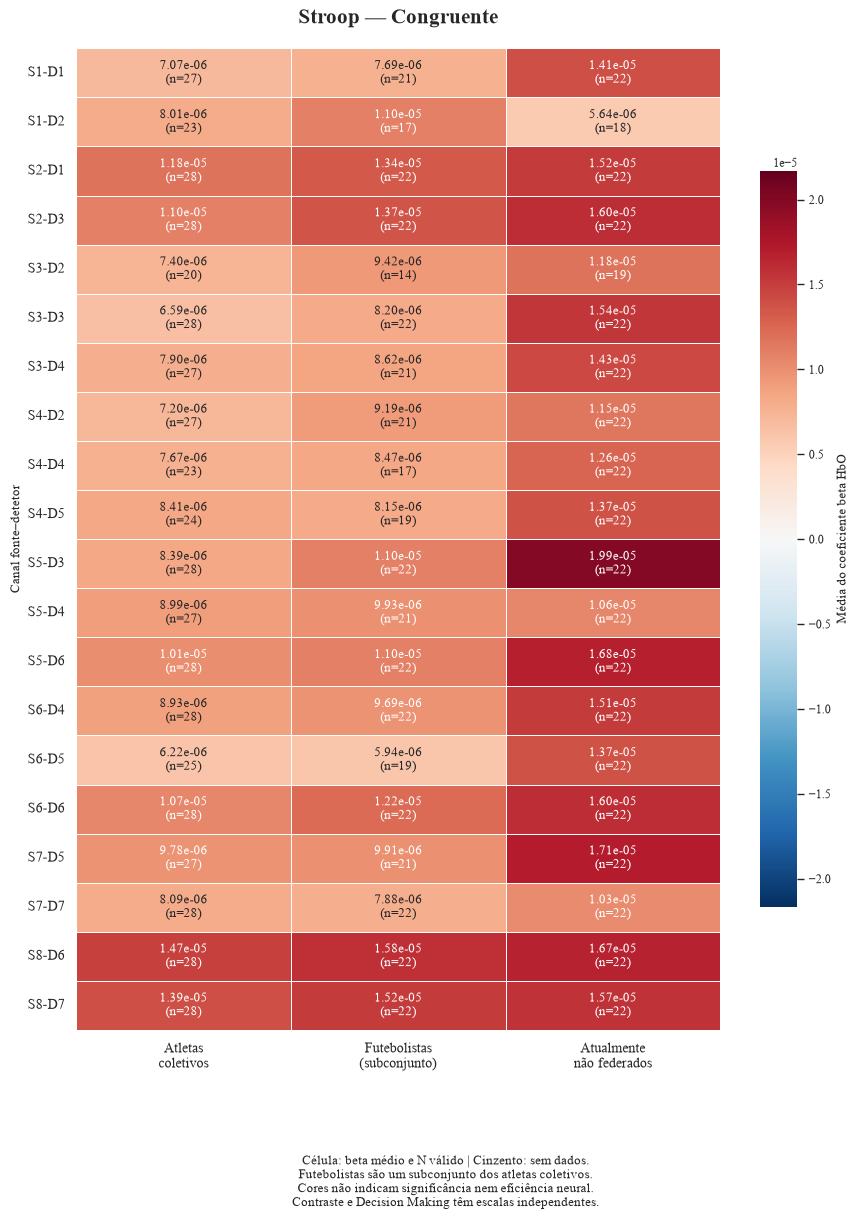

Heatmap guardado: Heatmap_HbO_Stroop_Inc.png | dtype: float64


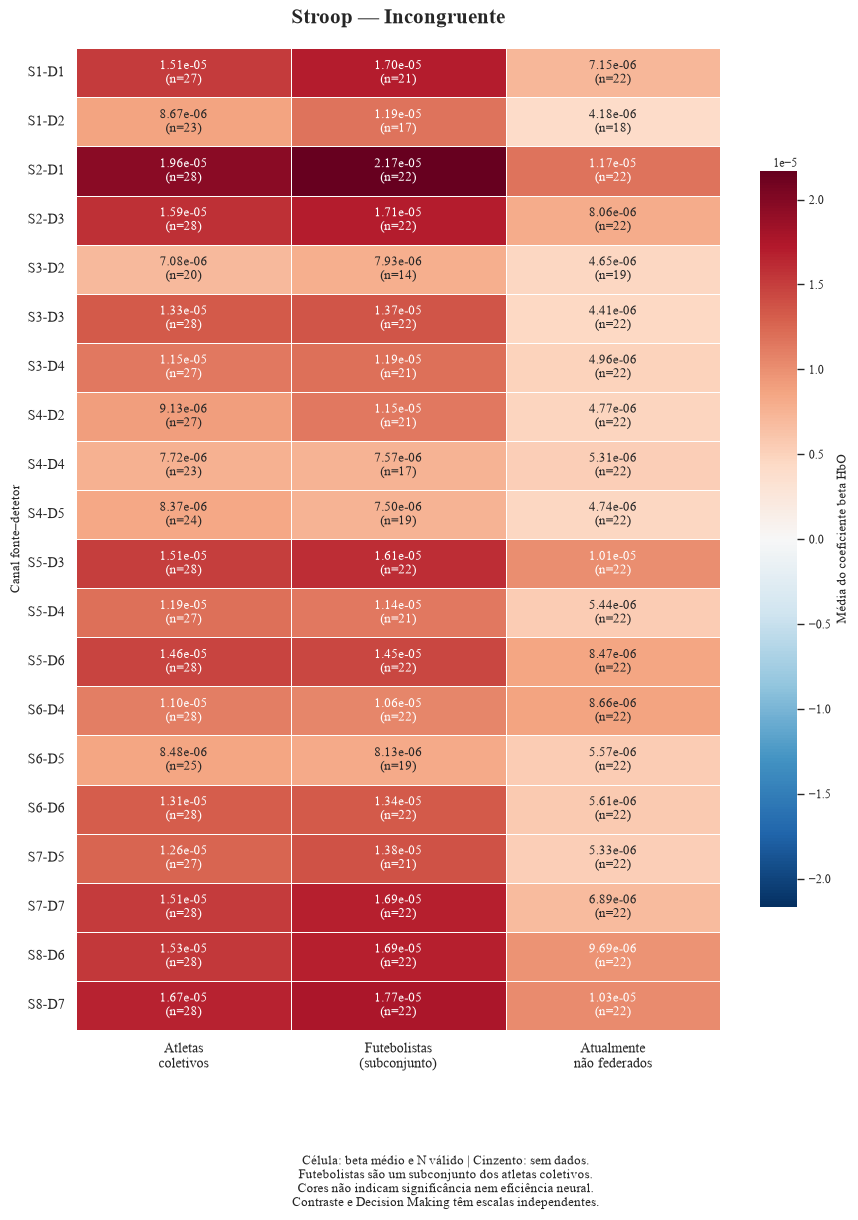

Heatmap guardado: Heatmap_HbO_Stroop_Inc-Con.png | dtype: float64


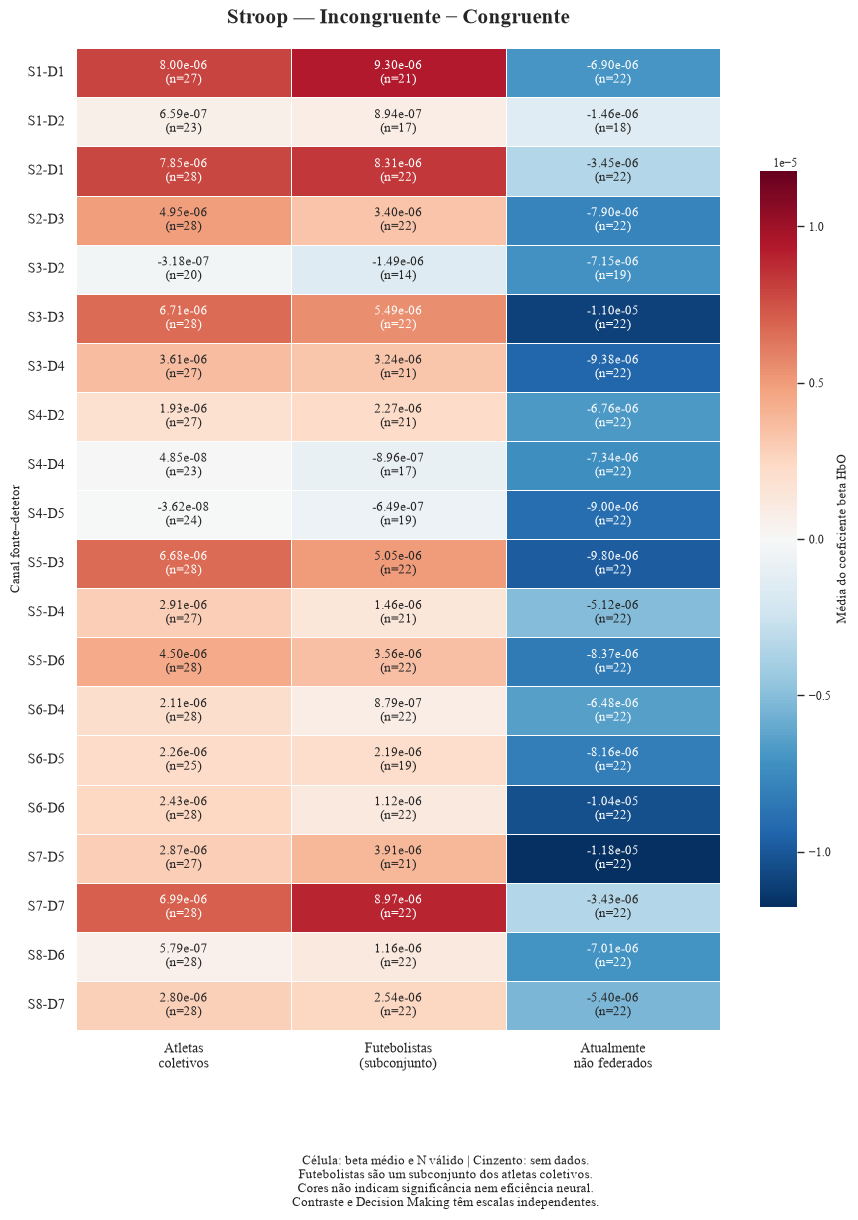

Heatmap guardado: Heatmap_HbO_DecisionMaking_Tarefa.png | dtype: float64


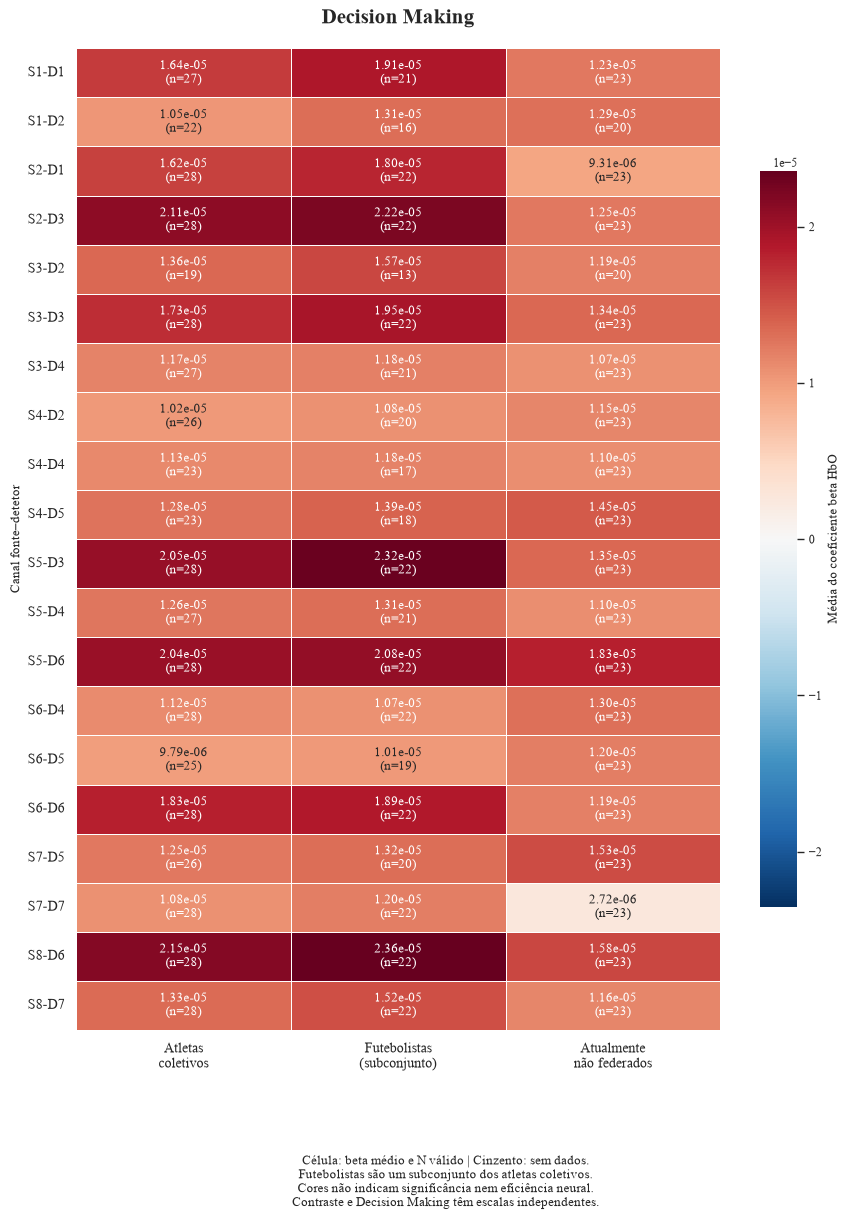


Execução concluída: quatro heatmaps, tabelas descritivas e auditoria por ID.

Resultados guardados em:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Heatmaps_Corticais


In [14]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# ==========================================================
# 1. Configuração
# ==========================================================
PASTA_DADOS = Path("../data_subjects")

PASTA_HEATMAPS = (
    PASTA_DADOS
    / "Resultados_Neurofisiologicos"
    / "Heatmaps_Corticais"
)
PASTA_HEATMAPS.mkdir(parents=True, exist_ok=True)

CAMINHO_DEMOGRAFIA = (
    PASTA_DADOS
    / "01_Dataset_Demografia_MIQ-3_Comportamentais.xlsx"
)

BASES_FISIOLOGIA = {
    "Stroop": "02_dataset_FINAL_SPA_fNIRS_Stroop",
    "DecisionMaking": "02_dataset_FINAL_SPA_fNIRS_DecisionMaking",
}

COL_ESTATUTO = (
    "É atualmente praticante federado de alguma modalidade desportiva?"
)

COL_TIPO = (
    "No caso de ser desportista federado, a sua modalidade principal é:"
)

COL_MODALIDADE = "Indique a modalidade principal"

MODALIDADES_COLETIVAS = {
    "futebol",
    "futsal",
    "andebol",
    "voleibol",
    "basquetebol",
}

MODALIDADES_FUTEBOL = {"futebol"}

GRUPOS = [
    "Coletivos",
    "Futebolistas",
    "Não federados",
]

ROTULOS_GRUPOS = [
    "Atletas\ncoletivos",
    "Futebolistas\n(subconjunto)",
    "Atualmente\nnão federados",
]

PAINEIS = [
    ("Stroop", "Con", "Stroop — Congruente"),
    ("Stroop", "Inc", "Stroop — Incongruente"),
    (
        "Stroop",
        "Inc-Con",
        "Stroop — Incongruente − Congruente",
    ),
    ("DecisionMaking", "Tarefa", "Decision Making"),
]

sns.set_theme(style="white", context="paper")
plt.rcParams["font.family"] = "Times New Roman"


# ==========================================================
# 2. Funções de leitura e validação
# ==========================================================
def limpar_colunas(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip()

    if df.columns.duplicated().any():
        raise ValueError("Existem nomes de colunas duplicados.")

    return df


def normalizar_ids(df, nome):
    df = limpar_colunas(df)

    if "ID" not in df.columns:
        raise ValueError(f"{nome}: falta a coluna ID.")

    ids = (
        df["ID"]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\.0$", "", regex=True)
    )

    if (ids.isna() | ids.eq("")).any():
        raise ValueError(f"{nome}: existem IDs vazios.")

    if ids.duplicated().any():
        duplicados = ids[ids.duplicated(keep=False)].tolist()
        raise ValueError(f"{nome}: IDs duplicados: {duplicados}")

    df["ID_Clean"] = ids
    return df


def numerico(serie):
    texto = (
        serie.astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
    )

    convertido = pd.to_numeric(texto, errors="coerce")

    valores = convertido.to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )

    valores[~np.isfinite(valores)] = np.nan

    return pd.Series(
        valores,
        index=serie.index,
        name=serie.name,
        dtype="float64",
    )


def matriz_float(df):
    return df.to_numpy(
        dtype=np.float64,
        na_value=np.nan,
    )


def ler_fisiologia(nome_base):
    caminho_csv = PASTA_DADOS / f"{nome_base}.csv"
    caminho_xlsx = PASTA_DADOS / f"{nome_base}.xlsx"

    if caminho_csv.exists():
        df = pd.read_csv(
            caminho_csv,
            sep=";",
            dtype="string",
        )

        if len(df.columns) < 5:
            df = pd.read_csv(
                caminho_csv,
                sep=",",
                dtype="string",
            )

    elif caminho_xlsx.exists():
        df = pd.read_excel(caminho_xlsx)

    else:
        raise FileNotFoundError(
            "Ficheiros de fisiologia nao encontrados:\n"
            f"{caminho_csv.resolve()}\n"
            f"{caminho_xlsx.resolve()}"
        )

    return normalizar_ids(df, nome_base)


# ==========================================================
# 3. Ler demografia
# ==========================================================
if not CAMINHO_DEMOGRAFIA.exists():
    raise FileNotFoundError(
        "Base demografica nao encontrada:\n"
        f"{CAMINHO_DEMOGRAFIA.resolve()}"
    )

with pd.ExcelFile(CAMINHO_DEMOGRAFIA) as livro:
    folha = (
        "Merge Dataset"
        if "Merge Dataset" in livro.sheet_names
        else 0
    )

    df_demo = pd.read_excel(
        livro,
        sheet_name=folha,
    )

df_demo = normalizar_ids(df_demo, "Base demográfica")

for coluna in [COL_ESTATUTO, COL_MODALIDADE]:
    if coluna not in df_demo.columns:
        raise ValueError(f"Falta a coluna: {coluna}")

estatuto = (
    df_demo[COL_ESTATUTO]
    .astype("string")
    .str.strip()
    .str.casefold()
)

modalidade = (
    df_demo[COL_MODALIDADE]
    .astype("string")
    .str.strip()
    .str.casefold()
)

if not estatuto.isin(["sim", "não", "nao"]).all():
    raise ValueError("Estatutos desportivos vazios ou nao reconhecidos.")

sem_modalidade = (
    estatuto.eq("sim")
    & (modalidade.isna() | modalidade.eq(""))
)

if sem_modalidade.any():
    raise ValueError("Existem federados sem modalidade indicada.")


# ==========================================================
# 4. Elegibilidade e grupos
# ==========================================================
if COL_TIPO in df_demo.columns:
    tipo = (
        df_demo[COL_TIPO]
        .astype("string")
        .str.strip()
        .str.casefold()
    )

    marca_individual = tipo.str.contains(
        "individual",
        regex=False,
        na=False,
    )

    marca_coletiva = tipo.str.contains(
        "coletiva",
        regex=False,
        na=False,
    )

    classificacao_valida = marca_individual ^ marca_coletiva

    classificacao_invalida = (
        estatuto.eq("sim")
        & ~classificacao_valida
    )

    if classificacao_invalida.any():
        ids_invalidos = df_demo.loc[
            classificacao_invalida,
            "ID_Clean",
        ].tolist()

        raise ValueError(
            "Federados com classificacao ausente ou ambigua: "
            f"{ids_invalidos}"
        )

    is_individual = marca_individual

else:
    is_individual = ~modalidade.isin(MODALIDADES_COLETIVAS)

excluir_individuais = estatuto.eq("sim") & is_individual

elegiveis = df_demo.loc[~excluir_individuais].copy()

estatuto_elegiveis = estatuto.loc[elegiveis.index]
modalidade_elegiveis = modalidade.loc[elegiveis.index]

is_coletivo = estatuto_elegiveis.eq("sim")
is_nao_federado = estatuto_elegiveis.isin(["não", "nao"])

is_futebolista = (
    is_coletivo
    & modalidade_elegiveis.isin(MODALIDADES_FUTEBOL)
)

partes = []

for grupo, mascara in [
    ("Coletivos", is_coletivo),
    ("Futebolistas", is_futebolista),
    ("Não federados", is_nao_federado),
]:
    parte = elegiveis.loc[
        mascara,
        ["ID_Clean"],
    ].copy()

    parte["Grupo"] = grupo
    partes.append(parte)

mapeamento = pd.concat(partes, ignore_index=True)

if mapeamento.duplicated(["ID_Clean", "Grupo"]).any():
    raise ValueError("Participante duplicado dentro do mesmo grupo.")

for grupo in GRUPOS:
    if not mapeamento["Grupo"].eq(grupo).any():
        raise ValueError(
            f"Grupo vazio: {grupo}. Rever as modalidades."
        )

print("Modalidades dos atletas coletivos elegíveis:")
print(
    elegiveis.loc[is_coletivo, COL_MODALIDADE]
    .value_counts(dropna=False)
)

print("\nParticipantes elegíveis por categoria:")
print(
    mapeamento.groupby("Grupo")["ID_Clean"]
    .nunique()
    .reindex(GRUPOS, fill_value=0)
)

print(
    "\nOs futebolistas também estão incluídos "
    "na categoria Atletas coletivos."
)


# ==========================================================
# 5. Dados individuais em formato longo
# ==========================================================
padrao = re.compile(
    r"^HbO_S(?P<Fonte>\d+)_D(?P<Detetor>\d+)"
    r"(?:_(?P<Condicao>Inc-Con|Inc|Con))?_Beta$"
)

bases_longas = []
auditorias = []

for tarefa, nome_base in BASES_FISIOLOGIA.items():
    fisiologia = ler_fisiologia(nome_base)
    metadados = []

    for coluna in fisiologia.columns:
        if not (
            coluna.startswith("HbO_")
            and coluna.endswith("_Beta")
        ):
            continue

        correspondencia = padrao.fullmatch(coluna)

        if correspondencia is None:
            raise ValueError(
                f"Nome de canal nao reconhecido: {coluna}"
            )

        info = correspondencia.groupdict()
        condicao = info["Condicao"] or "Tarefa"

        condicoes_esperadas = (
            {"Con", "Inc", "Inc-Con"}
            if tarefa == "Stroop"
            else {"Tarefa"}
        )

        if condicao not in condicoes_esperadas:
            raise ValueError(
                f"Condicao inesperada em {tarefa}: {coluna}"
            )

        metadados.append({
            "Variavel": coluna,
            "Canal": f"S{info['Fonte']}-D{info['Detetor']}",
            "Fonte": int(info["Fonte"]),
            "Detetor": int(info["Detetor"]),
            "Condicao": condicao,
        })

    if not metadados:
        raise ValueError(
            f"Sem coeficientes HbO em {tarefa}."
        )

    meta = pd.DataFrame(metadados)
    colunas_hbo = meta["Variavel"].tolist()

    for coluna in colunas_hbo:
        fisiologia[coluna] = numerico(fisiologia[coluna])

    auditoria = mapeamento.copy()
    auditoria["Tarefa"] = tarefa
    auditoria["Presente_fisiologia"] = (
        auditoria["ID_Clean"].isin(fisiologia["ID_Clean"])
    )

    auditorias.append(auditoria)

    master = mapeamento.merge(
        fisiologia[["ID_Clean"] + colunas_hbo],
        on="ID_Clean",
        how="inner",
        validate="many_to_one",
    )

    if master.empty:
        raise ValueError(
            f"{tarefa}: nenhum ID corresponde entre as bases."
        )

    longo = master.melt(
        id_vars=["ID_Clean", "Grupo"],
        value_vars=colunas_hbo,
        var_name="Variavel",
        value_name="Beta",
    ).merge(
        meta,
        on="Variavel",
        how="left",
        validate="many_to_one",
    )

    # Garante float64 também depois do melt.
    longo["Beta"] = numerico(longo["Beta"])
    longo["Tarefa"] = tarefa
    bases_longas.append(longo)

    print(f"\n{tarefa}: correspondência fisiológica por categoria")
    print(
        master.groupby("Grupo")["ID_Clean"]
        .nunique()
        .reindex(GRUPOS, fill_value=0)
    )

dados_longos = pd.concat(
    bases_longas,
    ignore_index=True,
)

dados_longos["Beta"] = numerico(dados_longos["Beta"])

auditoria_ids = pd.concat(
    auditorias,
    ignore_index=True,
)


# ==========================================================
# 6. Estatísticas e exportação
# ==========================================================
chaves = [
    "Tarefa",
    "Condicao",
    "Canal",
    "Fonte",
    "Detetor",
    "Grupo",
]

resumo = (
    dados_longos.groupby(chaves, dropna=False)["Beta"]
    .agg(
        Media="mean",
        Mediana="median",
        DP="std",
        N="count",
    )
    .reset_index()
)

for coluna in ["Media", "Mediana", "DP"]:
    resumo[coluna] = numerico(resumo[coluna])

resumo["N"] = resumo["N"].astype("int64")

for nome, tabela in [
    ("Resumo_HbO_por_Grupo", resumo),
    ("Dados_Individuais_HbO", dados_longos),
    ("Auditoria_IDs_Heatmaps", auditoria_ids),
]:
    tabela.to_csv(
        PASTA_HEATMAPS / f"{nome}.csv",
        index=False,
        encoding="utf-8-sig",
    )

with pd.ExcelWriter(
    PASTA_HEATMAPS / "Resumo_Heatmaps_HbO.xlsx"
) as writer:
    resumo.to_excel(
        writer,
        sheet_name="Resumo",
        index=False,
    )

    auditoria_ids.to_excel(
        writer,
        sheet_name="Auditoria_IDs",
        index=False,
    )

    dados_longos.to_excel(
        writer,
        sheet_name="Dados_individuais",
        index=False,
    )


# ==========================================================
# 7. Matrizes dos heatmaps
# ==========================================================
ordem_canais = (
    resumo[["Canal", "Fonte", "Detetor"]]
    .drop_duplicates()
    .sort_values(["Fonte", "Detetor"])["Canal"]
    .tolist()
)

matrizes = {}

for tarefa, condicao, titulo in PAINEIS:
    sub = resumo.loc[
        resumo["Tarefa"].eq(tarefa)
        & resumo["Condicao"].eq(condicao)
    ]

    if sub.empty:
        raise ValueError(
            f"Sem dados para {tarefa}, {condicao}."
        )

    medias_original = sub.pivot(
        index="Canal",
        columns="Grupo",
        values="Media",
    ).reindex(
        index=ordem_canais,
        columns=GRUPOS,
    )

    # Reconstrução explícita com dtype NumPy float64.
    medias = pd.DataFrame(
        matriz_float(medias_original),
        index=medias_original.index,
        columns=medias_original.columns,
        dtype="float64",
    )

    ns = sub.pivot(
        index="Canal",
        columns="Grupo",
        values="N",
    ).reindex(
        index=ordem_canais,
        columns=GRUPOS,
    ).fillna(0).astype("int64")

    matrizes[(tarefa, condicao)] = {
        "medias": medias,
        "ns": ns,
        "titulo": titulo,
    }

    medias.to_csv(
        PASTA_HEATMAPS / f"Medias_{tarefa}_{condicao}.csv",
        encoding="utf-8-sig",
    )

    ns.to_csv(
        PASTA_HEATMAPS / f"N_{tarefa}_{condicao}.csv",
        encoding="utf-8-sig",
    )


# ==========================================================
# 8. Escalas de cor simétricas
# ==========================================================
def limite_simetrico(lista_matrizes):
    valores = np.concatenate([
        matriz_float(matriz).ravel()
        for matriz in lista_matrizes
    ])

    valores = valores[np.isfinite(valores)]

    if valores.size == 0:
        raise ValueError(
            "Sem medias validas para definir a escala."
        )

    limite = float(np.max(np.abs(valores)))
    return limite if limite > 0 else 1.0


limite_stroop = limite_simetrico([
    matrizes[("Stroop", "Con")]["medias"],
    matrizes[("Stroop", "Inc")]["medias"],
])

limites = {
    ("Stroop", "Con"): limite_stroop,
    ("Stroop", "Inc"): limite_stroop,
    ("Stroop", "Inc-Con"): limite_simetrico([
        matrizes[("Stroop", "Inc-Con")]["medias"]
    ]),
    ("DecisionMaking", "Tarefa"): limite_simetrico([
        matrizes[("DecisionMaking", "Tarefa")]["medias"]
    ]),
}

escalas = pd.DataFrame([
    {
        "Tarefa": tarefa,
        "Condicao": condicao,
        "vmin": -limite,
        "vmax": limite,
    }
    for (tarefa, condicao), limite in limites.items()
])

escalas.to_csv(
    PASTA_HEATMAPS / "Escalas_de_Cor.csv",
    index=False,
    encoding="utf-8-sig",
)


# ==========================================================
# 9. Desenhar e guardar os quatro heatmaps
# ==========================================================
plt.close("all")

for chave, conteudo in matrizes.items():
    tarefa, condicao = chave
    medias = conteudo["medias"]
    ns = conteudo["ns"]
    limite = limites[chave]

    # Passa ao Seaborn um array NumPy numérico.
    valores = matriz_float(medias)
    mascara = ~np.isfinite(valores)
    contagens = ns.to_numpy(dtype=np.int64)

    if mascara.all():
        raise ValueError(
            f"Todos os valores sao omissos: {tarefa}, {condicao}."
        )

    anotacoes = np.full(
        valores.shape,
        "",
        dtype=object,
    )

    for i in range(valores.shape[0]):
        for j in range(valores.shape[1]):
            if not mascara[i, j]:
                anotacoes[i, j] = (
                    f"{valores[i, j]:.2e}\n"
                    f"(n={contagens[i, j]})"
                )

    altura = max(6, len(medias) * 0.52 + 2)
    fig, ax = plt.subplots(figsize=(9, altura))

    ax.set_facecolor("#e5e5e5")

    sns.heatmap(
        valores,
        mask=mascara,
        cmap="RdBu_r",
        center=0,
        vmin=-limite,
        vmax=limite,
        annot=anotacoes,
        fmt="",
        annot_kws={"size": 9},
        xticklabels=ROTULOS_GRUPOS,
        yticklabels=medias.index.tolist(),
        linewidths=0.5,
        linecolor="white",
        cbar_kws={
            "label": "Média do coeficiente beta HbO",
            "shrink": 0.75,
        },
        ax=ax,
    )

    ax.set_title(
        conteudo["titulo"],
        fontsize=15,
        fontweight="bold",
        pad=18,
    )

    ax.set_xlabel("")
    ax.set_ylabel("Canal fonte–detetor")

    ax.tick_params(
        axis="x",
        labelrotation=0,
        labelsize=10,
    )

    ax.tick_params(
        axis="y",
        labelrotation=0,
        labelsize=10,
    )

    nota = (
        "Célula: beta médio e N válido | Cinzento: sem dados.\n"
        "Futebolistas são um subconjunto dos atletas coletivos.\n"
        "Cores não indicam significância nem eficiência neural.\n"
        "Contraste e Decision Making têm escalas independentes."
    )

    fig.text(
        0.5,
        0.02,
        nota,
        ha="center",
        va="bottom",
        fontsize=9,
    )

    fig.tight_layout(rect=[0, 0.12, 1, 1])

    nome = f"Heatmap_HbO_{tarefa}_{condicao}"

    fig.savefig(
        PASTA_HEATMAPS / f"{nome}.png",
        dpi=300,
        bbox_inches="tight",
    )

    print(
        f"Heatmap guardado: {nome}.png "
        f"| dtype: {valores.dtype}"
    )

    plt.show()
    plt.close(fig)


# ==========================================================
# 10. Confirmação final
# ==========================================================
print(
    "\nExecução concluída: quatro heatmaps, "
    "tabelas descritivas e auditoria por ID."
)

print(
    f"\nResultados guardados em:\n"
    f"{PASTA_HEATMAPS.resolve()}"
)

Guardado: Mapa_Cabeca_2D_HbO_Stroop_Con.png


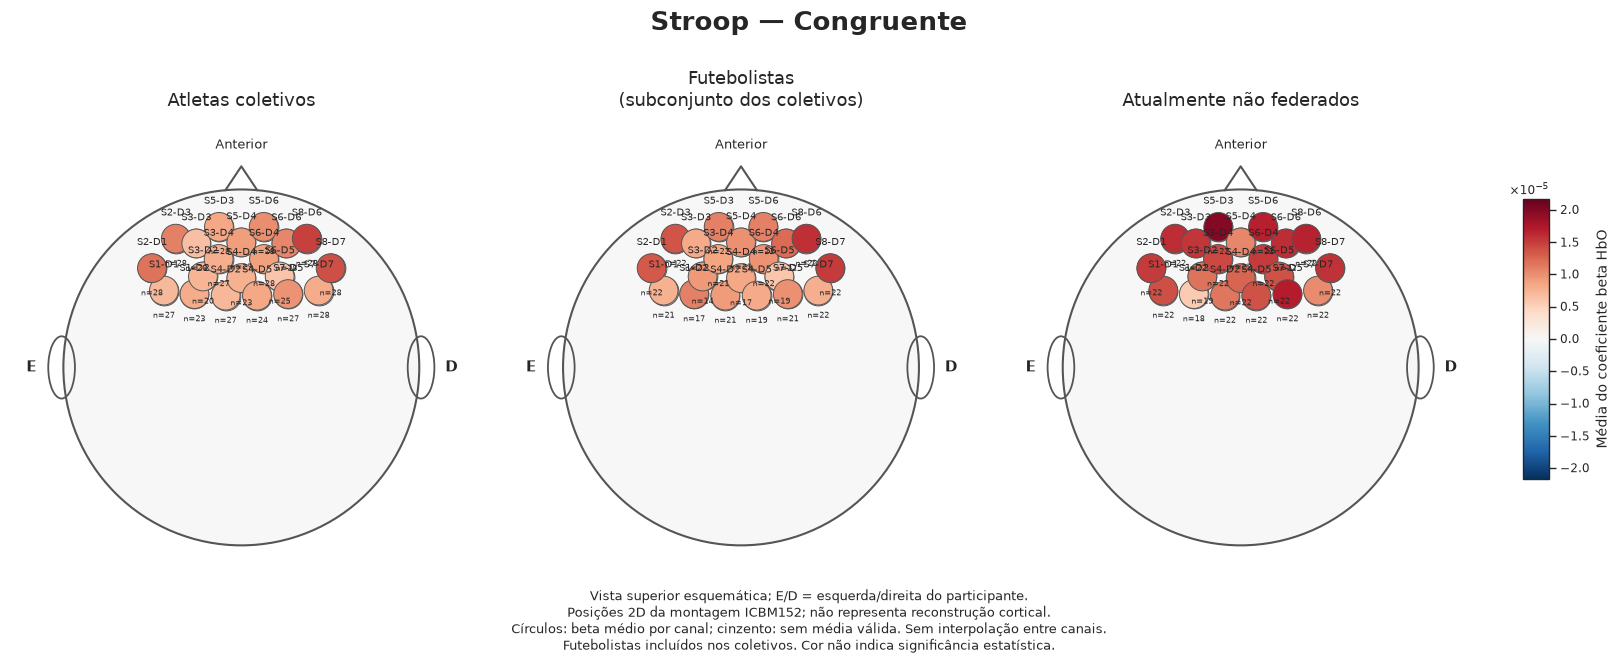

Guardado: Mapa_Cabeca_2D_HbO_Stroop_Inc.png


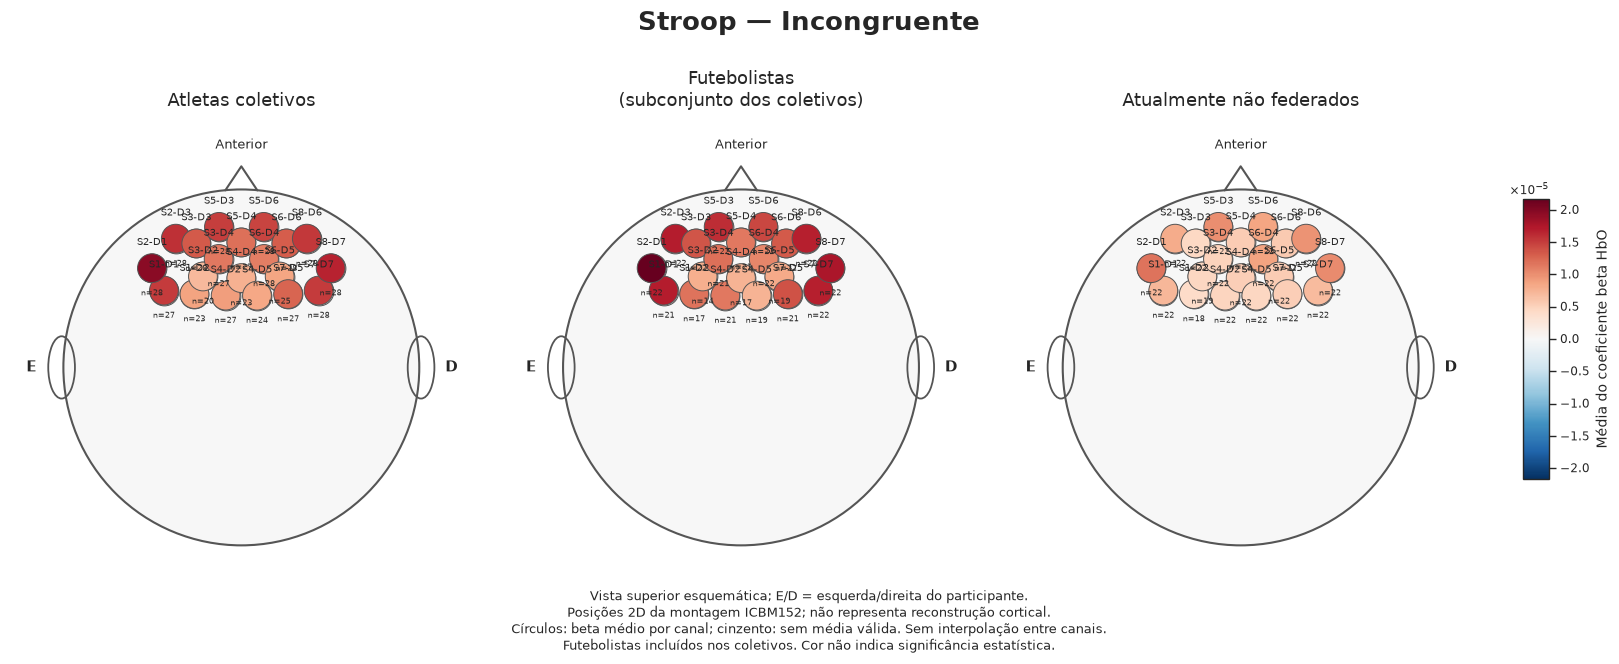

Guardado: Mapa_Cabeca_2D_HbO_Stroop_Inc-Con.png


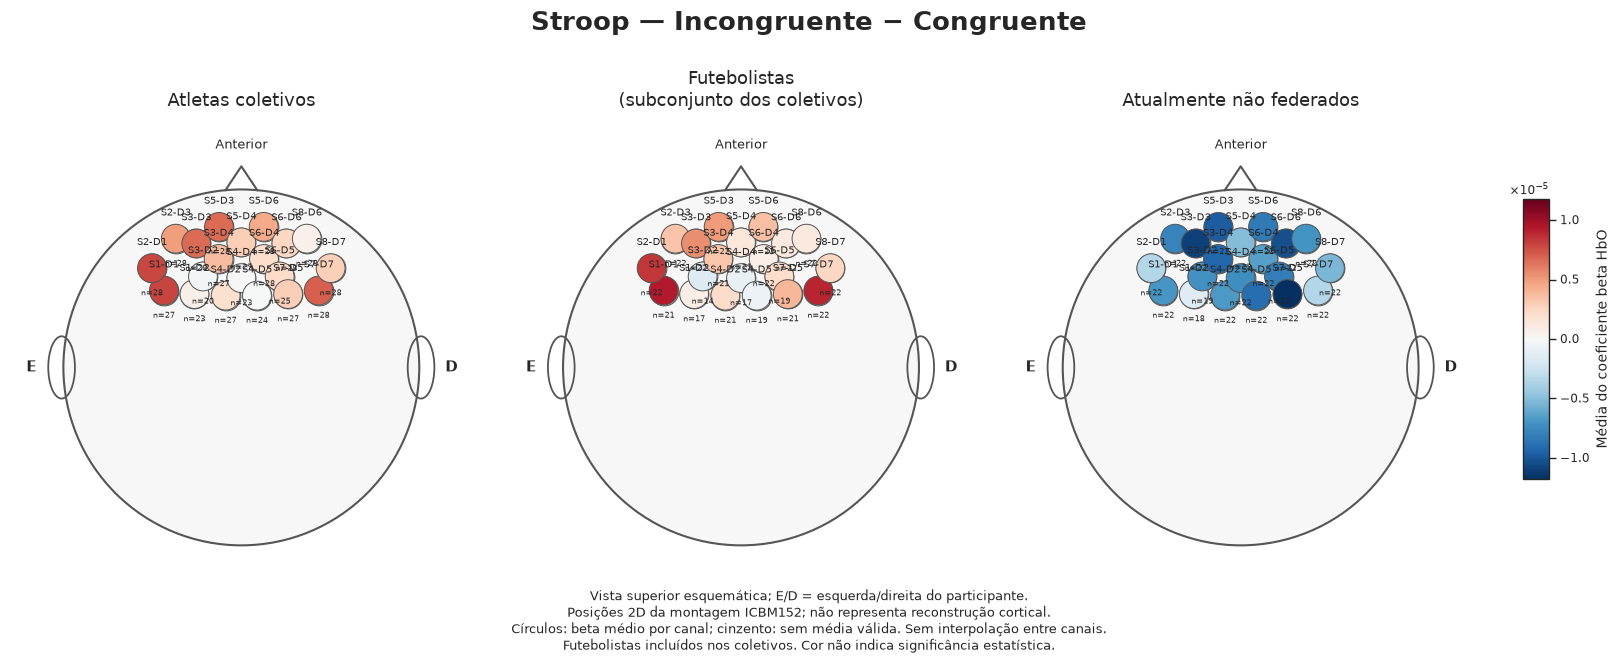

Guardado: Mapa_Cabeca_2D_HbO_DecisionMaking_Tarefa.png


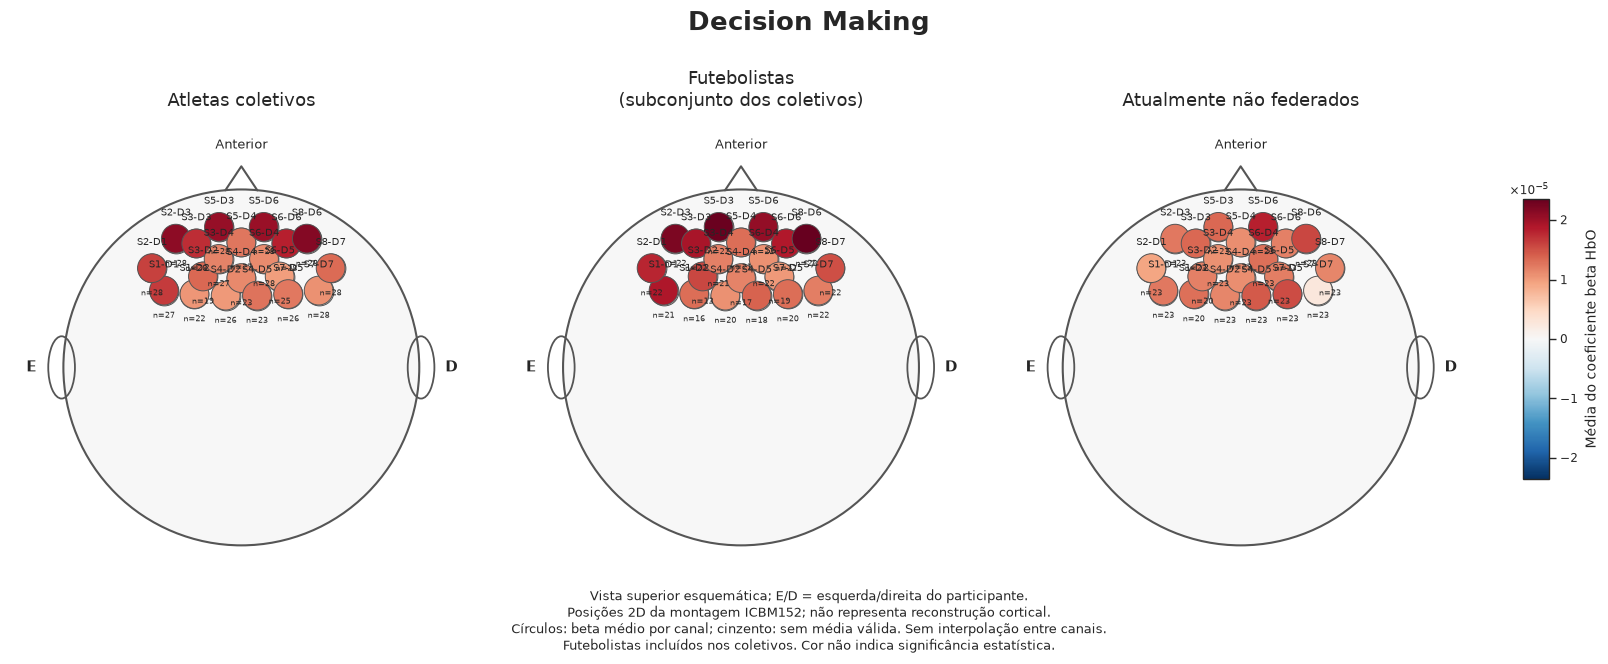


Execução concluída: quatro figuras com três grupos cada.

Pasta de saída:
C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Mapas_Cabeca_2D

Verificar que esta montagem e a numeração dos canais foram as mesmas em todos os participantes e tarefas.


In [15]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Circle, Ellipse
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import ScalarFormatter


# ==========================================================
# 1. Caminhos
# ==========================================================
PASTA_DADOS = Path("../data_subjects")

CAMINHO_JSON = (
    PASTA_DADOS / "2026-08-04_002_probeInfo.json"
)

PASTA_HEATMAPS = (
    PASTA_DADOS
    / "Resultados_Neurofisiologicos"
    / "Heatmaps_Corticais"
)

CAMINHO_RESUMO = (
    PASTA_HEATMAPS / "Resumo_HbO_por_Grupo.csv"
)

PASTA_SAIDA = (
    PASTA_DADOS
    / "Resultados_Neurofisiologicos"
    / "Mapas_Cabeca_2D"
)

PASTA_SAIDA.mkdir(parents=True, exist_ok=True)


# ==========================================================
# 2. Apresentação
# ==========================================================
GRUPOS = [
    "Coletivos",
    "Futebolistas",
    "Não federados",
]

TITULOS_GRUPOS = {
    "Coletivos": "Atletas coletivos",
    "Futebolistas": "Futebolistas\n(subconjunto dos coletivos)",
    "Não federados": "Atualmente não federados",
}

PAINEIS = [
    ("Stroop", "Con", "Stroop — Congruente"),
    ("Stroop", "Inc", "Stroop — Incongruente"),
    (
        "Stroop",
        "Inc-Con",
        "Stroop — Incongruente − Congruente",
    ),
    ("DecisionMaking", "Tarefa", "Decision Making"),
]

MOSTRAR_N = True
TAMANHO_CANAIS = 430
MAPA_CORES = "RdBu_r"

plt.rcParams["font.family"] = "DejaVu Sans"


# ==========================================================
# 3. Verificar ficheiros
# ==========================================================
for caminho in [CAMINHO_JSON, CAMINHO_RESUMO]:
    if not caminho.exists():
        raise FileNotFoundError(
            f"Ficheiro nao encontrado:\n{caminho.resolve()}"
        )


# ==========================================================
# 4. Ler montagem
# ==========================================================
with open(CAMINHO_JSON, "r", encoding="utf-8-sig") as ficheiro:
    montagem = json.load(ficheiro)

info = montagem["probeInfo"]
probes = info["probes"]

pares = np.asarray(
    probes["index_c"],
    dtype=int,
)

coords_2d = np.asarray(
    probes["coords_c2"],
    dtype=np.float64,
)

coords_3d = np.asarray(
    probes["coords_c3"],
    dtype=np.float64,
)

pares_curtos = {
    tuple(map(int, par))
    for par in probes.get("sdd_pairs", [])
}

if coords_2d.shape != (len(pares), 2):
    raise ValueError("Coordenadas 2D e lista de canais incompatíveis.")

if coords_3d.shape != (len(pares), 3):
    raise ValueError("Coordenadas 3D e lista de canais incompatíveis.")

if not np.isfinite(coords_2d).all():
    raise ValueError("Existem coordenadas 2D invalidas.")

geometria = pd.DataFrame({
    "Canal": [
        f"S{fonte}-D{detetor}"
        for fonte, detetor in pares
    ],
    "Fonte": pares[:, 0],
    "Detetor": pares[:, 1],
    "X_2D": coords_2d[:, 0],
    "Y_2D": coords_2d[:, 1],
    "X_MNI_mm": coords_3d[:, 0],
    "Y_MNI_mm": coords_3d[:, 1],
    "Z_MNI_mm": coords_3d[:, 2],
    "Curto": [
        tuple(par) in pares_curtos
        for par in pares
    ],
})

if geometria["Canal"].duplicated().any():
    raise ValueError("A montagem contém canais duplicados.")

# Mantém apenas os canais não classificados como curtos.
geometria = (
    geometria.loc[~geometria["Curto"]]
    .sort_values(["Fonte", "Detetor"])
    .reset_index(drop=True)
)


# ==========================================================
# 5. Ler as estatísticas já calculadas
# ==========================================================
resumo = pd.read_csv(CAMINHO_RESUMO)

colunas_obrigatorias = {
    "Tarefa",
    "Condicao",
    "Canal",
    "Grupo",
    "Media",
    "N",
}

faltam = colunas_obrigatorias - set(resumo.columns)

if faltam:
    raise ValueError(f"Colunas em falta: {sorted(faltam)}")

for coluna in ["Media", "N"]:
    resumo[coluna] = pd.to_numeric(
        resumo[coluna],
        errors="coerce",
    )

resumo["Media"] = resumo["Media"].replace(
    [np.inf, -np.inf],
    np.nan,
)

chaves = ["Tarefa", "Condicao", "Canal", "Grupo"]

if resumo.duplicated(chaves).any():
    raise ValueError("Existem estatísticas duplicadas por canal e grupo.")

canais_sem_posicao = (
    set(resumo["Canal"]) - set(geometria["Canal"])
)

if canais_sem_posicao:
    raise ValueError(
        "Canais do resumo sem posição não curta na montagem: "
        f"{sorted(canais_sem_posicao)}"
    )


# ==========================================================
# 6. Geometria do desenho
# ==========================================================
# Contorno esquemático, na mesma escala das coordenadas 2D.
# Não ajustar o centro à região frontal: manter a origem
# do sistema 2D fornecido pela montagem.
raio = (
    float(info["head_circumference"])
    / (2 * np.pi)
    / 10
)

distancias_2d = np.hypot(
    geometria["X_2D"],
    geometria["Y_2D"],
)

if (distancias_2d > raio).any():
    raise ValueError(
        "Há canais fora do contorno previsto. "
        "É necessário verificar a escala das coordenadas 2D."
    )


def desenhar_cabeca(ax):
    ax.add_patch(
        Circle(
            (0, 0),
            raio,
            facecolor="#f7f7f7",
            edgecolor="#555555",
            linewidth=1.5,
            zorder=0,
        )
    )

    # Nariz: anterior no topo.
    ax.plot(
        [-0.09 * raio, 0, 0.09 * raio],
        [0.995 * raio, 1.13 * raio, 0.995 * raio],
        color="#555555",
        linewidth=1.5,
        zorder=1,
    )

    for lado in [-1, 1]:
        ax.add_patch(
            Ellipse(
                (lado * 1.01 * raio, 0),
                width=0.15 * raio,
                height=0.35 * raio,
                facecolor="none",
                edgecolor="#555555",
                linewidth=1.3,
                zorder=0,
            )
        )

    ax.text(
        0,
        1.23 * raio,
        "Anterior",
        ha="center",
        fontsize=9,
    )

    ax.text(
        -1.18 * raio,
        0,
        "E",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

    ax.text(
        1.18 * raio,
        0,
        "D",
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
    )

    ax.set_xlim(-1.3 * raio, 1.3 * raio)
    ax.set_ylim(-1.08 * raio, 1.36 * raio)
    ax.set_aspect("equal")
    ax.axis("off")


def calcular_limite(tarefa, condicoes):
    selecao = resumo.loc[
        resumo["Tarefa"].eq(tarefa)
        & resumo["Condicao"].isin(condicoes)
        & resumo["Grupo"].isin(GRUPOS),
        "Media",
    ].to_numpy(dtype=np.float64)

    selecao = selecao[np.isfinite(selecao)]

    if selecao.size == 0:
        raise ValueError(
            f"Sem médias válidas: {tarefa}, {condicoes}"
        )

    limite = float(np.max(np.abs(selecao)))
    return limite if limite > 0 else 1.0


# Mesma escala para Congruente e Incongruente.
limite_stroop = calcular_limite(
    "Stroop",
    ["Con", "Inc"],
)

limites = {
    ("Stroop", "Con"): limite_stroop,
    ("Stroop", "Inc"): limite_stroop,
    ("Stroop", "Inc-Con"): calcular_limite(
        "Stroop",
        ["Inc-Con"],
    ),
    ("DecisionMaking", "Tarefa"): calcular_limite(
        "DecisionMaking",
        ["Tarefa"],
    ),
}


# ==========================================================
# 7. Criar mapas: três grupos por figura
# ==========================================================
tabelas_exportacao = []

for tarefa, condicao, titulo in PAINEIS:
    limite = limites[(tarefa, condicao)]

    norma = Normalize(
        vmin=-limite,
        vmax=limite,
    )

    fig, eixos = plt.subplots(
        1,
        3,
        figsize=(17, 7),
    )

    fig.subplots_adjust(
        left=0.03,
        right=0.89,
        bottom=0.15,
        top=0.82,
        wspace=0.08,
    )

    fig.suptitle(
        titulo,
        fontsize=19,
        fontweight="bold",
        y=0.96,
    )

    for ax, grupo in zip(eixos, GRUPOS):
        desenhar_cabeca(ax)

        sub = resumo.loc[
            resumo["Tarefa"].eq(tarefa)
            & resumo["Condicao"].eq(condicao)
            & resumo["Grupo"].eq(grupo),
            ["Canal", "Media", "N"],
        ]

        if sub.empty:
            raise ValueError(
                f"Sem dados: {tarefa}, {condicao}, {grupo}"
            )

        dados = geometria.merge(
            sub,
            on="Canal",
            how="left",
            validate="one_to_one",
        )

        dados["Tarefa"] = tarefa
        dados["Condicao"] = condicao
        dados["Grupo"] = grupo

        tabelas_exportacao.append(dados.copy())

        x = dados["X_2D"].to_numpy(dtype=np.float64)
        y = dados["Y_2D"].to_numpy(dtype=np.float64)

        valores = dados["Media"].to_numpy(
            dtype=np.float64,
            na_value=np.nan,
        )

        validos = np.isfinite(valores)

        # Todos os canais em cinzento; os válidos sobrepõem-se.
        ax.scatter(
            x,
            y,
            s=TAMANHO_CANAIS,
            color="#cfcfcf",
            edgecolors="#555555",
            linewidths=0.7,
            zorder=3,
        )

        ax.scatter(
            x[validos],
            y[validos],
            c=valores[validos],
            s=TAMANHO_CANAIS,
            cmap=MAPA_CORES,
            norm=norma,
            edgecolors="#555555",
            linewidths=0.7,
            zorder=4,
        )

        for linha in dados.itertuples(index=False):
            ax.annotate(
                linha.Canal,
                (linha.X_2D, linha.Y_2D),
                xytext=(0, 15),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=7,
                zorder=5,
            )

            if MOSTRAR_N and pd.notna(linha.Media):
                ax.annotate(
                    f"n={int(linha.N)}",
                    (linha.X_2D, linha.Y_2D),
                    xytext=(0, -15),
                    textcoords="offset points",
                    ha="center",
                    va="top",
                    fontsize=6,
                    zorder=5,
                )

        ax.set_title(
            TITULOS_GRUPOS[grupo],
            fontsize=13,
            pad=14,
        )

    eixo_barra = fig.add_axes(
        [0.92, 0.29, 0.015, 0.40]
    )

    mapeamento_cores = ScalarMappable(
        norm=norma,
        cmap=MAPA_CORES,
    )

    mapeamento_cores.set_array([])

    barra = fig.colorbar(
        mapeamento_cores,
        cax=eixo_barra,
    )

    barra.set_label(
        "Média do coeficiente beta HbO",
        fontsize=10,
    )

    formato = ScalarFormatter(useMathText=True)
    formato.set_powerlimits((0, 0))

    barra.formatter = formato
    barra.update_ticks()

    nota = (
        "Vista superior esquemática; E/D = esquerda/direita do participante.\n"
        "Posições 2D da montagem ICBM152; não representa reconstrução cortical.\n"
        "Círculos: beta médio por canal; cinzento: sem média válida. "
        "Sem interpolação entre canais.\n"
        "Futebolistas incluídos nos coletivos. "
        "Cor não indica significância estatística."
    )

    fig.text(
        0.5,
        0.04,
        nota,
        ha="center",
        va="bottom",
        fontsize=9,
    )

    nome = f"Mapa_Cabeca_2D_HbO_{tarefa}_{condicao}"

    fig.savefig(
        PASTA_SAIDA / f"{nome}.png",
        dpi=300,
        bbox_inches="tight",
    )

    print(f"Guardado: {nome}.png")

    plt.show()
    plt.close(fig)


# ==========================================================
# 8. Exportar coordenadas e valores utilizados
# ==========================================================
geometria.to_csv(
    PASTA_SAIDA / "Coordenadas_Canais.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.concat(
    tabelas_exportacao,
    ignore_index=True,
).to_csv(
    PASTA_SAIDA / "Valores_Mapas_Cabeca_2D.csv",
    index=False,
    encoding="utf-8-sig",
)

pd.DataFrame([
    {
        "Tarefa": tarefa,
        "Condicao": condicao,
        "vmin": -limite,
        "vmax": limite,
    }
    for (tarefa, condicao), limite in limites.items()
]).to_csv(
    PASTA_SAIDA / "Escalas_Cor_Mapas_2D.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nExecução concluída: quatro figuras com três grupos cada.")
print(f"\nPasta de saída:\n{PASTA_SAIDA.resolve()}")
print(
    "\nVerificar que esta montagem e a numeração dos canais "
    "foram as mesmas em todos os participantes e tarefas."
)